# 02 · HMDA：模型比较与下一轮提升

先运行 `01_hmda_data_preparation.ipynb`。这本 notebook 继续承载保留的模型和后续实验；原始 56 列、固定五折和数据哈希保持统一。**默认 `review`，不会训练。**

建议顺序：先用 `full` 同轮跑 R1/R2/XGBoost 参照；再逐个试 DTI、地区收入、LTV 差值；然后对 XGBoost 或 CatBoost 做有预算的折内搜索；最后检查固定权重融合、校准和资源较重的新模型。只有你打开对应模式才会训练。


## 1. 配置

从项目根目录启动。`HMDA_RUN_MODE=review` 只校验；`smoke` 只查通路；`full` 跑所选模型完整五折；`search` 在每个外折的训练集内搜索；`advanced` 和 `calibrate` 是可选实验。每次输出单独保存于 `artifacts/models/`。模型列表用 `HMDA_MODELS` 设置，例如 `CatBoost_R1,CatBoost_R1_DTI`。训练和最终导出由你启动。


In [24]:
from google.colab import drive
import os

drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis')
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis


In [ ]:
!nvidia-smi

In [25]:
# ============================================================
# Colab dependencies
# ============================================================

%pip install -q catboost xgboost lightgbm

import catboost
import xgboost
import lightgbm

print("CatBoost:", catboost.__version__)
print("XGBoost:", xgboost.__version__)
print("LightGBM:", lightgbm.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.7 MB/s eta 0:00:00
CatBoost: 1.2.10
XGBoost: 3.4.1
LightGBM: 4.6.0


In [26]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import sys
import time
import warnings

import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted

PROJECT_DIR = Path.cwd().resolve()
DATA_DIR = Path(os.environ.get('HMDA_DATA_DIR', str(PROJECT_DIR))).expanduser().resolve()
OUTPUT_ROOT = Path(os.environ.get('HMDA_OUTPUT_DIR', str(PROJECT_DIR))).expanduser().resolve()
PREPARED_DIR = OUTPUT_ROOT / 'artifacts' / 'prepared'
HISTORY_DIR = PROJECT_DIR / 'history'
# 只改这两项；本机发热时保持 review，远端训练时改为 full。
NOTEBOOK_RUN_MODE = 'review'
NOTEBOOK_MODELS = ['CatBoost_R1', 'CatBoost_R2', 'XGBoost']
RUN_MODE = os.environ.get('HMDA_RUN_MODE', NOTEBOOK_RUN_MODE).strip().lower()
SELECTED_MODELS = [s.strip() for s in os.environ.get(
    'HMDA_MODELS', ','.join(NOTEBOOK_MODELS)).split(',') if s.strip()]
SMOKE_ROWS = int(os.environ.get('HMDA_SMOKE_ROWS', '2000'))
SMOKE_FOLDS = int(os.environ.get('HMDA_SMOKE_FOLDS', '2'))
N_THREADS = int(os.environ.get('HMDA_THREADS', '4'))
MODEL_SEED = 42
INNER_STOP_FRACTION = 0.15
MAX_ROUNDS = 1500
EARLY_STOPPING_ROUNDS = 100

# 显式开启后，只允许在本次完整五折成功结束后拟合全量数据并写出本地 CSV。
RUN_MODE = 'full'
SELECTED_MODELS = ['CatBoost_R1', 'CatBoost_R2', 'XGBoost']

if RUN_MODE not in {'review', 'smoke', 'full', 'search', 'advanced', 'calibrate'}:
    raise ValueError('HMDA_RUN_MODE 必须是 review / smoke / full / search / advanced / calibrate')
if not SELECTED_MODELS or len(SELECTED_MODELS) != len(set(SELECTED_MODELS)):
    raise ValueError('模型列表不能为空或重复')
if SMOKE_ROWS < 100 or not 1 <= SMOKE_FOLDS <= 5 or N_THREADS < 1:
    raise ValueError('smoke rows >= 100；folds 在 1..5；threads >= 1')
if FIT_FINAL_MODEL and RUN_MODE != 'full':
    raise ValueError('生成最终预测需要 RUN_MODE="full"')
print(f'模式：{RUN_MODE}；模型：{SELECTED_MODELS}')
print(f'Python：{sys.executable}\n读取：{PREPARED_DIR}\n输出：{OUTPUT_ROOT / "artifacts" / "models"}')
if RUN_MODE == 'smoke':
    display(Markdown('**当前为 SMOKE：小样本、少轮数、部分折，仅检查执行链路。**'))

模式：full；模型：['CatBoost_R1', 'CatBoost_R2', 'XGBoost']
Python：/usr/bin/python3
读取：/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis/artifacts/prepared
输出：/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis/artifacts/models


## 2. 校验 notebook 之间的数据契约

拒绝哈希不匹配、ID 重复或错位、特征变化、错误标签和不同的折分配。数值缺失仍为 `NaN`，类别缺失仍为 `MISSING`；不在这里做全数据插补或编码。折分配必须逐行等于 `StratifiedKFold(5, shuffle=True, random_state=42)` 的结果。

In [27]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


# DATA_CONTRACT_LOADER
manifest_path = PREPARED_DIR / 'manifest.json'
if not manifest_path.exists():
    raise FileNotFoundError(f'请先运行 01 数据 notebook：缺少 {manifest_path}')
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
schema = json.loads((PREPARED_DIR / 'schema.json').read_text(encoding='utf-8'))
require(set(manifest['source_files']) == {'train.csv', 'test.csv', 'sample_submission.csv'}, '原始文件哈希清单不完整')
require(set(manifest['output_files']) == {'train_features.csv', 'test_features.csv', 'train_labels.csv', 'test_ids.csv', 'folds.csv', 'audit.csv', 'schema.json'}, '准备文件哈希清单不完整')
for name, info in manifest['output_files'].items():
    path = PREPARED_DIR / name
    require(path.is_file(), f'缺少准备产物：{name}')
    require(sha256_file(path) == info['sha256'], f'准备产物哈希不匹配：{name}')
for name, info in manifest['source_files'].items():
    path = DATA_DIR / name
    require(path.is_file(), f'缺少原始文件：{path}；请设置 HMDA_DATA_DIR')
    require(sha256_file(path) == info['sha256'], f'原始文件已变化：{name}；请重新运行 01')

require(manifest['schema_version'] == schema['schema_version'] == '1.0', '不支持的数据契约版本')
require(manifest['seed'] == 42 and manifest['n_splits'] == 5, 'manifest 折配置不匹配')
FEATURE_COLUMNS = schema['feature_columns']
NUMERIC_COLUMNS = schema['numeric_columns']
CATEGORICAL_COLUMNS = schema['categorical_columns']
require(len(FEATURE_COLUMNS) == 56 and len(set(FEATURE_COLUMNS)) == 56, '预期 56 个唯一原始特征')
require(len(NUMERIC_COLUMNS) == 13 and len(CATEGORICAL_COLUMNS) == 43, '预期数值 13 / 类别 43')
require(set(NUMERIC_COLUMNS).isdisjoint(CATEGORICAL_COLUMNS), '数值和类别字段不能重叠')
require(set(NUMERIC_COLUMNS + CATEGORICAL_COLUMNS) == set(FEATURE_COLUMNS), 'schema 分组不完整')
require(not {'id', 'accepted'} & set(FEATURE_COLUMNS), 'ID 和标签不能作为特征')


def read_features(path):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    require(frame.columns.tolist() == FEATURE_COLUMNS, f'字段或顺序不匹配：{path.name}')
    for col in NUMERIC_COLUMNS:
        frame[col] = pd.to_numeric(frame[col].replace('', np.nan), errors='raise').astype('float64')
    require(not np.isinf(frame[NUMERIC_COLUMNS].to_numpy()).any(), '数值包含无穷大')
    require(not frame[CATEGORICAL_COLUMNS].eq('').any().any(), '类别不允许空字符串')
    for col in CATEGORICAL_COLUMNS:
        frame[col] = frame[col].astype(object)
    return frame


X = read_features(PREPARED_DIR / 'train_features.csv')
X_test = read_features(PREPARED_DIR / 'test_features.csv')
labels = pd.read_csv(PREPARED_DIR / 'train_labels.csv', dtype=str, keep_default_na=False)
test_ids_frame = pd.read_csv(PREPARED_DIR / 'test_ids.csv', dtype=str, keep_default_na=False)
fold_frame = pd.read_csv(PREPARED_DIR / 'folds.csv', dtype=str, keep_default_na=False)
require(labels.columns.tolist() == ['id', 'accepted'], 'train_labels 必须是 id,accepted')
require(test_ids_frame.columns.tolist() == ['id'], 'test_ids 必须只有 id')
require(fold_frame.columns.tolist() == ['id', 'fold'], 'folds 必须是 id,fold')
require(len(X) == len(labels) == len(fold_frame), '训练数据长度不匹配')
require(len(X_test) == len(test_ids_frame), '测试数据长度不匹配')
require(len(X) == manifest['n_rows']['train'] and len(X_test) == manifest['n_rows']['test'], 'manifest 行数不匹配')
train_ids = labels['id'].copy()
test_ids = test_ids_frame['id'].copy()
require(train_ids.is_unique and test_ids.is_unique, 'ID 重复')
require(train_ids.ne('').all() and test_ids.ne('').all(), 'ID 不能为空')
require(train_ids.equals(fold_frame['id']), 'folds ID 顺序不一致')
require(set(train_ids).isdisjoint(test_ids), '训练与测试 ID 重叠')
require(set(labels['accepted']) == {'0', '1'}, 'accepted 必须包含 0 和 1')
y = labels['accepted'].astype('int8')
require(set(fold_frame['fold']) == {'1', '2', '3', '4', '5'}, '必须存在且仅存在 1..5 折')
fold_assignment = fold_frame['fold'].astype('int8').to_numpy()

raw_train_identity = pd.read_csv(DATA_DIR / 'train.csv', usecols=['id', 'accepted'], dtype=str, keep_default_na=False)
raw_test_identity = pd.read_csv(DATA_DIR / 'test.csv', usecols=['id'], dtype=str, keep_default_na=False)
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype=str, keep_default_na=False)
require(train_ids.equals(raw_train_identity['id']), 'train_features 对应的 ID 顺序与原始 train 不符')
require(labels['accepted'].equals(raw_train_identity['accepted']), '标签与原始 train 不符')
require(test_ids.equals(raw_test_identity['id']), 'test ID 顺序与原始 test 不符')
require(sample_submission.columns.tolist() == ['id', 'accepted'], 'submission 列必须为 id,accepted')
require(test_ids.equals(sample_submission['id']), 'test ID 顺序与 sample_submission 不符')
expected_folds = np.zeros(len(y), dtype=np.int8)
for fold, (_, validation_idx) in enumerate(StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42).split(X, y), start=1):
    expected_folds[validation_idx] = fold
require(np.array_equal(fold_assignment, expected_folds), '固定五折分配校验失败')
DATA_HASHES = {'manifest.json': sha256_file(manifest_path),
               **{name: info['sha256'] for name, info in manifest['output_files'].items()}}
print(f'契约通过：训练 {len(X):,} 行，测试 {len(X_test):,} 行，56 特征；五折 seed=42。')
display(pd.crosstab(fold_assignment, y, rownames=['fold'], colnames=['accepted']))

契约通过：训练 105,000 行，测试 45,000 行，56 特征；五折 seed=42。


accepted,0,1
fold,,
1,3151,17849
2,3151,17849
3,3151,17849
4,3151,17849
5,3152,17848


## 3. 历史证据：按实验协议阅读

`history/evidence.csv` 是旧结果的索引。`protocol` 不同的行不能直接用于严格排名；其中非树模型的单次小样本验证只在 `single_split_auc` 中记录。旧 CSV / notebook 的完整证据仍在归档目录。

保留依据：LR 保留 N2_INT 与 LTV 高值标记；RF 保留 N2 基准；CatBoost R1 保留原始 56 特征和固定 1600 轮，R2 仅作深度 8 候选；XGBoost 与 LightGBM 保留最近 CPU 比较的参数。

**新的统一协议**：所有模型共享数据 notebook 的 seed 42 外层五折。XGBoost / LightGBM 用外层训练集的内部 15% 选择轮数，然后用完整外层训练集重新拟合。旧 `first_tier` 用 seed 20260923，早停后没有完整外层重拟合；旧分数不会被当作新主线的复现结果。
**环境复现说明：**历史 LR 使用 scikit-learn 1.6.1，当前统一环境为 1.8.0（Python/NumPy/SciPy 版本也不同）。本次完整 LR 五折均值为 0.900203，旧记录为 0.900261；同一环境下新旧代码的完整第 1 折处理矩阵和预测完全一致，历史环境中新代码也精确复现原第 1 折。详见 `history/lr_reproduction_check.json`。


In [28]:
evidence_path = HISTORY_DIR / 'evidence.csv'
if evidence_path.exists():
    historical_evidence = pd.read_csv(evidence_path)
    require('protocol' in historical_evidence.columns, '历史证据缺少 protocol')
    for protocol, part in historical_evidence.groupby('protocol', sort=False):
        display(Markdown(f'**历史协议：`{protocol}`**'))
        display(part.drop(columns=['protocol']).reset_index(drop=True))
else:
    display(Markdown('历史证据索引尚未放入 `history/evidence.csv`；当前不会虚构历史分数。'))

**历史协议：`CV5_seed42_full_outer_train_fixed`**

,model,mean_fold_auc,std_fold_auc,pooled_oof_auc,fit_seconds,source,role,caveat,single_split_auc
0,RF_N2,0.907429,0.005446,0.907260,92.057910,14_hmda_summary.csv,optional_ensemble_baseline,Historical development CV; selected using prio...,NaN
1,LR_N2_INT_LTV_FLAGS,0.900261,0.005829,0.900202,9.732281,14_hmda_summary.csv,default_interpretable_baseline,Historical development CV; selected using prio...,NaN
2,CatBoost_R1_1600_D6_L2_3,0.915190,0.005776,0.915113,1226.908015,17_hmda_summary.csv,default_tree_baseline,"Same development dataset, different fold seeds...",NaN
3,CatBoost_R2_1600_D8_L2_3,0.915940,0.005760,0.915855,1712.001816,17_hmda_summary.csv,optional_accuracy_candidate,"Same development dataset, different fold seeds...",NaN


**历史协议：`CV5_seed2026_full_outer_train_fixed`**

,model,mean_fold_auc,std_fold_auc,pooled_oof_auc,fit_seconds,source,role,caveat,single_split_auc
0,CatBoost_R1_1600_D6_L2_3,0.915357,0.003378,0.915282,1129.007551,16_hmda_catboost_summary.csv,default_tree_baseline,"Same development dataset, different fold seeds...",NaN
1,CatBoost_R2_1600_D8_L2_3,0.916258,0.003314,0.916157,1608.491076,16_hmda_catboost_summary.csv,optional_accuracy_candidate,"Same development dataset, different fold seeds...",NaN


**历史协议：`CV5_seed20260923_inner15pct_no_refit`**

,model,mean_fold_auc,std_fold_auc,pooled_oof_auc,fit_seconds,source,role,caveat,single_split_auc
0,CatBoost_inner_stop,0.913977,0.002073,0.913949,910.132362,first_tier_cpu_comparison_20260923/results/202...,strong_tree_reference,Outer validation not used for stopping; model ...,NaN
1,XGBoost_inner_stop,0.910379,0.001653,0.910285,20.439846,first_tier_cpu_comparison_20260923/results/202...,default_speed_candidate,Outer validation not used for stopping; model ...,NaN
2,LightGBM_inner_stop,0.901636,0.001993,0.901182,6.673574,first_tier_cpu_comparison_20260923/results/202...,optional_speed_reference,Outer validation not used for stopping; model ...,NaN


**历史协议：`single_split_seed20260920_train20000_valid5000`**

,model,mean_fold_auc,std_fold_auc,pooled_oof_auc,fit_seconds,source,role,caveat,single_split_auc
0,GAM,NaN,NaN,NaN,0.432578,20_hmda_six_model_results/20260920T155308_4111...,future_extension_unconfirmed,One development holdout; not OOF or full-data ...,0.89161


## 4. LR 与 RF 的折内表示

严格保留 notebook 12 / 14 的实现：去掉 `county_code` / `derived_msa-md`，增加三个缺失/特殊代码标记。LR 增加 `DTI=…|LOAN=…` 类别交互和训练折 P99 / P99.9 的 LTV 高值标记；LTV 本身不截断。RF 不使用这两个 LTV 标记，也不加 DTI 交互。

数值分支依次为：训练折中位数插补并增加缺失指示器 → 金额与房产价值 `log1p`、收入有符号 `log1p` → 标准化。类别分支只在训练折拟合 one-hot，忽略验证时的新类别。

In [29]:
def representation_spec(model_name):
    numeric = list(NUMERIC_COLUMNS) + ['county_is_missing', 'msa_is_missing', 'msa_is_99999']
    categorical = [c for c in CATEGORICAL_COLUMNS if c not in {'county_code', 'derived_msa-md'}]
    if model_name == 'LR':
        numeric += ['ltv_above_p99', 'ltv_above_p999']
        categorical += ['dti_loan_type']
    elif model_name != 'RF':
        raise ValueError(model_name)
    return numeric, categorical


class LinearTreeRepresentation(BaseEstimator, TransformerMixin):
    def __init__(self, model_name='LR'):
        self.model_name = model_name

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        representation_spec(self.model_name)
        if self.model_name == 'LR':
            observed = X['loan_to_value_ratio'].dropna()
            require(len(observed) > 0 and observed.ge(0).all(), 'LR 训练折 LTV 全缺失或出现负值')
            self.ltv_p99_ = float(observed.quantile(.99, interpolation='linear'))
            self.ltv_p999_ = float(observed.quantile(.999, interpolation='linear'))
        return self

    def transform(self, X):
        check_is_fitted(self, 'feature_names_in_')
        require(X.columns.tolist() == self.feature_names_in_.tolist(), '输入列顺序变化')
        out = X.copy()
        out['county_is_missing'] = out['county_code'].eq('MISSING').astype(float)
        out['msa_is_missing'] = out['derived_msa-md'].eq('MISSING').astype(float)
        out['msa_is_99999'] = out['derived_msa-md'].eq('99999').astype(float)
        out = out.drop(columns=['county_code', 'derived_msa-md'])
        if self.model_name == 'LR':
            out['dti_loan_type'] = ('DTI=' + out['debt_to_income_ratio'].astype(str)
                                    + '|LOAN=' + out['loan_type'].astype(str)).astype(object)
            out['ltv_above_p99'] = out['loan_to_value_ratio'].gt(self.ltv_p99_).astype(float)
            out['ltv_above_p999'] = out['loan_to_value_ratio'].gt(self.ltv_p999_).astype(float)
        return out


class BaseLogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, numeric_columns):
        self.numeric_columns = numeric_columns

    def fit(self, values, y=None):
        self.n_features_in_ = np.asarray(values).shape[1]
        return self

    def transform(self, values):
        check_is_fitted(self, 'n_features_in_')
        out = np.asarray(values, dtype=float).copy()
        for col in ['loan_amount', 'property_value']:
            idx = self.numeric_columns.index(col)
            require(np.all(out[:, idx] >= 0), f'{col} 不允许负数')
            out[:, idx] = np.log1p(out[:, idx])
        idx = self.numeric_columns.index('income')
        out[:, idx] = np.sign(out[:, idx]) * np.log1p(np.abs(out[:, idx]))
        require(np.isfinite(out).all(), '变换后存在非有限数值')
        return out

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else
                          [f'x{i}' for i in range(self.n_features_in_)], dtype=object)


def make_sklearn_pipeline(name):
    numeric, categorical = representation_spec(name)
    preprocessor = ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
            ('logs', BaseLogTransformer(tuple(numeric))),
            ('scaler', StandardScaler()),
        ]), numeric),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical),
    ], sparse_threshold=1.0)
    estimator = (LogisticRegression(**MODEL_REGISTRY['LR']['params']) if name == 'LR'
                 else RandomForestClassifier(**effective_params(name)))
    return Pipeline([('representation', LinearTreeRepresentation(name)),
                     ('preprocess', preprocessor), ('model', estimator)])

## 5. 可开关的候选特征

以下规则仅使用申请记录本身的信息，保留原始 56 列。每个外层训练折单独创建变换对象；`DTI` 上下界、报告形式、相对地区收入及 LTV 两种口径差值都可单独消融。先比较一个块，再考虑组合。


In [30]:
# TransformerMixin and check_is_fitted. No label or population statistic is used.

FEATURE_BLOCK_COLUMNS = {
    'dti_bounds': (('dti_lower', 'dti_upper'), ()),
    'dti_form': ((), ('dti_report_form',)),
    'relative_income': (('income_relative_to_msa_median',), ('income_relative_state',)),
    'ltv_gap': (('ltv_reported_minus_implied',), ('ltv_gap_state',)),
}
DTI_BOUNDS_AND_FORM = {
    **{str(value): (float(value), float(value), 'exact') for value in range(36, 50)},
    '20%-<30%': (20.0, 30.0, 'finite_interval'),
    '30%-<36%': (30.0, 36.0, 'finite_interval'),
    '50%-60%': (50.0, 60.0, 'finite_interval'),
    '<20%': (np.nan, 20.0, 'one_sided_interval'),
    '>60%': (60.0, np.nan, 'one_sided_interval'),
    'MISSING': (np.nan, np.nan, 'missing'),
}


class HmdaFeatureVariant(BaseEstimator, TransformerMixin):
    """Fold-local, deterministic candidate features; raw prepared columns survive unchanged.

    `fit` only validates and freezes the input schema. Calling it on each outer
    training fold makes the API safe to extend later with fitted transformations.
    """

    def __init__(self, blocks=(), feature_columns=None):
        self.blocks = blocks
        self.feature_columns = feature_columns

    def _validate_schema(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError('HmdaFeatureVariant expects a pandas DataFrame')
        expected = list(self.feature_columns)
        if X.columns.tolist() != expected or len(expected) != len(set(expected)):
            raise ValueError('Feature variant input columns or order differ from prepared schema')
        if {'id', 'accepted'} & set(expected):
            raise ValueError('ID and target must not be model features')
        for column in self.required_numeric_columns_:
            if not pd.api.types.is_numeric_dtype(X[column]):
                raise TypeError(f'{column} must be numeric after notebook 01 preparation')
            if np.isinf(X[column].to_numpy(dtype=float)).any():
                raise ValueError(f'{column} contains infinity')
        if self.uses_dti_:
            dti = X['debt_to_income_ratio']
            unknown = set(dti.unique().tolist()) - set(DTI_BOUNDS_AND_FORM)
            if unknown:
                raise ValueError(f'Unknown DTI categories: {sorted(map(str, unknown))}')

    def fit(self, X, y=None):
        if self.feature_columns is None:
            raise ValueError('Pass schema["feature_columns"] to feature_columns')
        blocks = tuple(self.blocks)
        if len(blocks) != len(set(blocks)) or set(blocks) - set(FEATURE_BLOCK_COLUMNS):
            raise ValueError(f'Unknown or repeated feature blocks: {blocks}')
        self.blocks_ = blocks
        self.uses_dti_ = bool({'dti_bounds', 'dti_form'} & set(blocks))
        required = set()
        if self.uses_dti_:
            required.add('debt_to_income_ratio')
        if 'relative_income' in blocks:
            required.update(('income', 'ffiec_msa_md_median_family_income'))
        if 'ltv_gap' in blocks:
            required.update(('loan_to_value_ratio', 'loan_amount', 'property_value'))
        missing = required - set(self.feature_columns)
        if missing:
            raise ValueError(f'Required prepared fields are absent: {sorted(missing)}')
        self.required_numeric_columns_ = tuple(sorted(required - {'debt_to_income_ratio'}))
        added_numeric, added_categorical = [], []
        for block in blocks:
            numeric, categorical = FEATURE_BLOCK_COLUMNS[block]
            added_numeric.extend(numeric)
            added_categorical.extend(categorical)
        self.numeric_columns_added_ = tuple(added_numeric)
        self.categorical_columns_added_ = tuple(added_categorical)
        self.output_columns_ = tuple(self.feature_columns) + self.numeric_columns_added_ + self.categorical_columns_added_
        if len(self.output_columns_) != len(set(self.output_columns_)):
            raise ValueError('Derived feature names collide with prepared schema')
        self._validate_schema(X)
        self.feature_names_in_ = np.asarray(self.feature_columns, dtype=object)
        return self

    def transform(self, X):
        check_is_fitted(self, 'feature_names_in_')
        self._validate_schema(X)
        out = X.copy()
        if self.uses_dti_:
            dti_parts = X['debt_to_income_ratio'].map(DTI_BOUNDS_AND_FORM)
            if 'dti_bounds' in self.blocks_:
                out['dti_lower'] = dti_parts.map(lambda item: item[0]).astype('float64')
                out['dti_upper'] = dti_parts.map(lambda item: item[1]).astype('float64')
            if 'dti_form' in self.blocks_:
                out['dti_report_form'] = dti_parts.map(lambda item: item[2]).astype(object)
        if 'relative_income' in self.blocks_:
            income = X['income'].to_numpy(dtype=float)
            median = X['ffiec_msa_md_median_family_income'].to_numpy(dtype=float)
            valid = np.isfinite(income) & np.isfinite(median) & (median > 0)
            ratio = np.full(len(X), np.nan, dtype='float64')
            np.divide(1000.0 * income, median, out=ratio, where=valid)
            out['income_relative_to_msa_median'] = ratio
            out['income_relative_state'] = pd.Series(np.select(
                [~np.isfinite(income), ~np.isfinite(median), median <= 0],
                ['income_missing', 'regional_median_missing', 'regional_median_nonpositive'],
                default='valid'), index=X.index, dtype=object)
        if 'ltv_gap' in self.blocks_:
            reported = X['loan_to_value_ratio'].to_numpy(dtype=float)
            loan = X['loan_amount'].to_numpy(dtype=float)
            property_value = X['property_value'].to_numpy(dtype=float)
            valid = np.isfinite(reported) & np.isfinite(loan) & np.isfinite(property_value) & (property_value > 0)
            gap = np.full(len(X), np.nan, dtype='float64')
            np.divide(100.0 * loan, property_value, out=gap, where=valid)
            gap[valid] = reported[valid] - gap[valid]
            out['ltv_reported_minus_implied'] = gap
            out['ltv_gap_state'] = pd.Series(np.select(
                [~np.isfinite(reported), ~np.isfinite(loan), ~np.isfinite(property_value), property_value <= 0],
                ['reported_ltv_missing', 'loan_amount_missing', 'property_value_missing', 'property_value_nonpositive'],
                default='valid'), index=X.index, dtype=object)
        out = out.loc[:, self.output_columns_]
        if out.columns.tolist() != list(self.output_columns_) or not out.index.equals(X.index):
            raise AssertionError('Derived feature schema or row index changed')
        return out

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, 'feature_names_in_')
        if input_features is not None and list(input_features) != list(self.feature_names_in_):
            raise ValueError('Input feature names differ from fit schema')
        return np.asarray(self.output_columns_, dtype=object)


# First candidate comparisons: (), ('dti_bounds',),
# ('dti_bounds', 'dti_form'), ('relative_income',), ('ltv_gap',).
# For each fold: variant = HmdaFeatureVariant(blocks, FEATURE_COLUMNS).fit(x_fit)
# x_fit_v, x_eval_v = variant.transform(x_fit), variant.transform(x_eval)
# numeric_v = NUMERIC_COLUMNS + list(variant.numeric_columns_added_)
# categorical_v = CATEGORICAL_COLUMNS + list(variant.categorical_columns_added_)
# Use categorical_v for CatBoost cat_features and NativeCategoryVocabulary.


## 6. 可扩展模型注册表

注册表是后续增加模型或新变体的入口。模型依赖只在选中且实际训练时导入；缺少依赖会明确报错，不会悄悄跳过模型。XGBoost 首选当前环境；也允许用 `HMDA_XGBOOST_PATH` 指定已有依赖目录，或显式显示并复用归档中已有的依赖。

CatBoost 直接使用类别字符串和数值 NaN；XGBoost / LightGBM 的类别词表由本次拟合数据决定，未见类别转为缺失。内层选轮和外层重拟合分别学习自己的词表。

In [31]:
MODEL_REGISTRY = {
    'LR': {'family': 'sklearn', 'role': '解释性基线：N2_INT + LTV flags',
           'params': dict(solver='lbfgs', C=1.0, max_iter=2000,
                          class_weight=None, random_state=MODEL_SEED)},
    'RF': {'family': 'sklearn', 'role': '可选非线性对照：N2',
           'params': dict(n_estimators=300, max_depth=16, min_samples_leaf=20,
                          max_features=.2, class_weight=None, random_state=MODEL_SEED,
                          n_jobs=N_THREADS)},
    'CatBoost_R1': {'family': 'catboost', 'role': '主模型：原始56特征',
                    'params': dict(iterations=1600, depth=6, learning_rate=.05,
                                   l2_leaf_reg=3., loss_function='Logloss', eval_metric='AUC',
                                   nan_mode='Min', random_seed=MODEL_SEED, task_type='CPU',
                                   thread_count=N_THREADS, use_best_model=False,
                                   allow_writing_files=False, verbose=False)},
    'CatBoost_R2': {'family': 'catboost', 'role': '可选容量候选：depth8',
                    'params': dict(iterations=1600, depth=8, learning_rate=.05,
                                   l2_leaf_reg=3., loss_function='Logloss', eval_metric='AUC',
                                   nan_mode='Min', random_seed=MODEL_SEED, task_type='CPU',
                                   thread_count=N_THREADS, use_best_model=False,
                                   allow_writing_files=False, verbose=False)},
    'XGBoost': {'family': 'native', 'role': '强候选：内层早停后完整外层重拟合',
                'params': dict(objective='binary:logistic', tree_method='hist', device='cpu',
                               enable_categorical=True, n_estimators=MAX_ROUNDS,
                               learning_rate=.05, max_depth=6, min_child_weight=10,
                               subsample=.85, colsample_bytree=.85, reg_lambda=3.,
                               max_cat_to_onehot=8, max_cat_threshold=64, eval_metric='auc',
                               n_jobs=N_THREADS, random_state=MODEL_SEED)},
    'LightGBM': {'family': 'native', 'role': '可选快速对照：内层早停后重拟合',
                 'params': dict(objective='binary', n_estimators=MAX_ROUNDS,
                                learning_rate=.05, num_leaves=31, min_child_samples=50,
                                subsample=.85, subsample_freq=1, colsample_bytree=.85,
                                reg_lambda=3., cat_smooth=10., metric='auc',
                                first_metric_only=True, n_jobs=N_THREADS,
                                random_state=MODEL_SEED, verbosity=-1)},
}
# 候选特征默认关闭；把同名模型与 R1 放在同一次 full 运行里配对比较。
for name, blocks, role in [
    ('CatBoost_R1_DTI', ('dti_bounds',), 'R1 + DTI 上下界'),
    ('CatBoost_R1_DTI_Form', ('dti_bounds', 'dti_form'), 'R1 + DTI 上下界和报告形式'),
    ('CatBoost_R1_Income', ('relative_income',), 'R1 + 相对地区收入'),
    ('CatBoost_R1_LTV_Gap', ('ltv_gap',), 'R1 + 两种 LTV 口径差'),
]:
    MODEL_REGISTRY[name] = {'family': 'catboost', 'role': role,
                            'params': dict(MODEL_REGISTRY['CatBoost_R1']['params']),
                            'feature_blocks': blocks}
for name, seed in [('CatBoost_R2_seed7', 7), ('CatBoost_R2_seed2026', 2026)]:
    params = dict(MODEL_REGISTRY['CatBoost_R2']['params'])
    params['random_seed'] = seed
    MODEL_REGISTRY[name] = {'family': 'catboost', 'role': f'R2 模型种子 {seed}', 'params': params}

require(set(SELECTED_MODELS) <= set(MODEL_REGISTRY), f'未知模型：{set(SELECTED_MODELS) - set(MODEL_REGISTRY)}')


def effective_params(name):
    params = dict(MODEL_REGISTRY[name]['params'])
    if RUN_MODE == 'smoke':
        if 'iterations' in params:
            params['iterations'] = 30
        if 'n_estimators' in params:
            params['n_estimators'] = 30
    return params


def load_xgboost():
    try:
        return importlib.import_module('xgboost')
    except ModuleNotFoundError as exc:
        if exc.name != 'xgboost':
            raise
    explicit = os.environ.get('HMDA_XGBOOST_PATH')
    fallback = PROJECT_DIR / 'archive' / 'legacy_20260929' / 'first_tier_cpu_comparison_20260923' / 'deps'
    dependency_dir = Path(explicit).expanduser().resolve() if explicit else fallback
    if not (dependency_dir / 'xgboost').is_dir():
        raise ModuleNotFoundError('选中了 XGBoost，但当前环境缺少 xgboost。请安装 requirements.txt，'
                                  '或显式设置 HMDA_XGBOOST_PATH 为已有依赖目录。')
    print(f'显式复用 XGBoost 依赖目录：{dependency_dir}')
    sys.path.insert(0, str(dependency_dir))
    return importlib.import_module('xgboost')


DEPENDENCY_MODULES = {}
if RUN_MODE in {'smoke', 'full', 'search', 'calibrate'}:
    if any(MODEL_REGISTRY[name]['family'] == 'catboost' for name in SELECTED_MODELS) or RUN_MODE == 'calibrate':
        DEPENDENCY_MODULES['catboost'] = importlib.import_module('catboost')
    if RUN_MODE in {'smoke', 'full', 'search'} and 'XGBoost' in SELECTED_MODELS:
        DEPENDENCY_MODULES['xgboost'] = load_xgboost()
    if RUN_MODE in {'smoke', 'full', 'search'} and 'LightGBM' in SELECTED_MODELS:
        DEPENDENCY_MODULES['lightgbm'] = importlib.import_module('lightgbm')

display(pd.DataFrame([{'model': name, 'selected': name in SELECTED_MODELS,
                      'role': entry['role'], 'effective_params': effective_params(name)}
                     for name, entry in MODEL_REGISTRY.items()]))

,model,selected,role,effective_params
0,LR,False,解释性基线：N2_INT + LTV flags,"{'solver': 'lbfgs', 'C': 1.0, 'max_iter': 2000..."
1,RF,False,可选非线性对照：N2,"{'n_estimators': 300, 'max_depth': 16, 'min_sa..."
2,CatBoost_R1,True,主模型：原始56特征,"{'iterations': 1600, 'depth': 6, 'learning_rat..."
3,CatBoost_R2,True,可选容量候选：depth8,"{'iterations': 1600, 'depth': 8, 'learning_rat..."
4,XGBoost,True,强候选：内层早停后完整外层重拟合,"{'objective': 'binary:logistic', 'tree_method'..."
5,LightGBM,False,可选快速对照：内层早停后重拟合,"{'objective': 'binary', 'n_estimators': 1500, ..."
6,CatBoost_R1_DTI,False,R1 + DTI 上下界,"{'iterations': 1600, 'depth': 6, 'learning_rat..."
7,CatBoost_R1_DTI_Form,False,R1 + DTI 上下界和报告形式,"{'iterations': 1600, 'depth': 6, 'learning_rat..."
8,CatBoost_R1_Income,False,R1 + 相对地区收入,"{'iterations': 1600, 'depth': 6, 'learning_rat..."
9,CatBoost_R1_LTV_Gap,False,R1 + 两种 LTV 口径差,"{'iterations': 1600, 'depth': 6, 'learning_rat..."


In [32]:
class NativeCategoryVocabulary:
    def fit(self, frame):
        self.columns_ = frame.columns.tolist()
        self.vocabularies_ = {col: sorted(frame[col].unique().tolist()) for col in CATEGORICAL_COLUMNS}
        return self

    def transform(self, frame):
        require(frame.columns.tolist() == self.columns_, '原生类别输入列发生变化')
        out = frame.copy()
        for col, vocabulary in self.vocabularies_.items():
            dtype = pd.CategoricalDtype(categories=vocabulary, ordered=False)
            out[col] = out[col].where(out[col].isin(vocabulary), other=pd.NA).astype(dtype)
        return out


def make_booster(name, n_rounds=None, early_stop=False):
    params = effective_params(name)
    if n_rounds is not None:
        params['n_estimators'] = int(n_rounds)
    if name == 'XGBoost':
        if early_stop:
            params['early_stopping_rounds'] = 5 if RUN_MODE == 'smoke' else EARLY_STOPPING_ROUNDS
        return DEPENDENCY_MODULES['xgboost'].XGBClassifier(**params)
    if name == 'LightGBM':
        return DEPENDENCY_MODULES['lightgbm'].LGBMClassifier(**params)
    raise ValueError(name)


def check_probability(probability):
    p = np.asarray(probability, dtype=float)
    require(np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all(), '无效预测概率')
    return p


def fit_model(name, x_fit, y_fit, x_eval, *, fixed_rounds=None):
    """返回预测、已拟合对象、词表、可审计元数据；永不接受外层验证标签。"""
    started = time.perf_counter()
    info = {'best_round': None, 'inner_fit_rows': None, 'inner_stop_rows': None,
            'refit_rows': len(x_fit), 'ltv_p99': None, 'ltv_p999': None,
            'convergence_warnings': 0}
    vocabulary = None
    family = MODEL_REGISTRY[name]['family']
    if family == 'sklearn':
        model = make_sklearn_pipeline(name)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            model.fit(x_fit, y_fit)
        info['convergence_warnings'] = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
        for warning in caught:
            warnings.warn(str(warning.message), warning.category)
        if name == 'LR':
            representation = model.named_steps['representation']
            info.update(ltv_p99=representation.ltv_p99_, ltv_p999=representation.ltv_p999_)
            info['best_round'] = int(model.named_steps['model'].n_iter_[0])
        else:
            info['best_round'] = int(model.named_steps['model'].n_estimators)
        probability = model.predict_proba(x_eval)[:, 1]
    elif family == 'catboost':
        # 固定轮数，无 eval_set；完整外层训练集参与拟合。
        blocks = MODEL_REGISTRY[name].get('feature_blocks', ())
        cat_columns = list(CATEGORICAL_COLUMNS)
        if blocks:
            vocabulary = HmdaFeatureVariant(blocks, FEATURE_COLUMNS).fit(x_fit)
            x_fit = vocabulary.transform(x_fit)
            x_eval = vocabulary.transform(x_eval)
            cat_columns += list(vocabulary.categorical_columns_added_)
        model = DEPENDENCY_MODULES['catboost'].CatBoostClassifier(**effective_params(name))
        model.fit(x_fit, y_fit, cat_features=cat_columns)
        info['feature_blocks'] = list(blocks)
        info['best_round'] = int(model.tree_count_)
        probability = model.predict_proba(x_eval)[:, 1]
    elif family == 'native':
        if fixed_rounds is None:
            fit_idx, stop_idx = train_test_split(np.arange(len(x_fit)),
                test_size=INNER_STOP_FRACTION, stratify=np.asarray(y_fit), random_state=MODEL_SEED)
            inner_fit, inner_stop = x_fit.iloc[fit_idx], x_fit.iloc[stop_idx]
            inner_vocab = NativeCategoryVocabulary().fit(inner_fit)
            stop_model = make_booster(name, early_stop=True)
            fit_native = inner_vocab.transform(inner_fit)
            stop_native = inner_vocab.transform(inner_stop)
            if name == 'XGBoost':
                stop_model.fit(fit_native, np.asarray(y_fit)[fit_idx],
                               eval_set=[(stop_native, np.asarray(y_fit)[stop_idx])], verbose=False)
                chosen_round = int(stop_model.best_iteration + 1)
            else:
                callback = DEPENDENCY_MODULES['lightgbm'].early_stopping(
                    5 if RUN_MODE == 'smoke' else EARLY_STOPPING_ROUNDS,
                    first_metric_only=True, verbose=False)
                stop_model.fit(fit_native, np.asarray(y_fit)[fit_idx],
                               eval_set=[(stop_native, np.asarray(y_fit)[stop_idx])],
                               eval_metric='auc', callbacks=[callback])
                chosen_round = int(stop_model.best_iteration_ or effective_params(name)['n_estimators'])
            info.update(inner_fit_rows=len(fit_idx), inner_stop_rows=len(stop_idx))
        else:
            chosen_round = int(fixed_rounds)
        require(chosen_round >= 1, '选出的训练轮数必须 >= 1')
        info['best_round'] = chosen_round
        # 使用内层选出的轮数，在完整外层训练集上重新学习类别词表并重拟合。
        vocabulary = NativeCategoryVocabulary().fit(x_fit)
        model = make_booster(name, n_rounds=chosen_round, early_stop=False)
        model.fit(vocabulary.transform(x_fit), y_fit)
        probability = model.predict_proba(vocabulary.transform(x_eval))[:, 1]
    else:
        raise ValueError(f'未实现的模型 family：{family}')
    info['fit_seconds'] = time.perf_counter() - started
    return check_probability(probability), model, vocabulary, info

## 7. 折内有限搜索（可选）

`search` 模式下，设置 `HMDA_SEARCH_TARGETS=XGBoost` 或 `CatBoost_R1`。预算默认每外折 XGBoost 24、CatBoost 16 个候选；先用 `HMDA_SEARCH_XGB_TRIALS=2` 或 `HMDA_SEARCH_CAT_TRIALS=2` 测耗时。搜索、早停和参数选择都只用该外折训练部分，最终在整个外折训练集重拟合。其他选中模型按原配置运行，作为同轮参照。开发数据已多次用于选择，分数仍须谨慎解释。


In [33]:
# Insert this cell after fit_model and before the outer-CV cell in Notebook 02.
# Existing Notebook 02 imports (Path, hashlib, json, time, np, pd,
# StratifiedKFold, train_test_split, roc_auc_score) and globals are reused.
# Defining these functions never fits a model; only RUN_MODE='search' starts it.

SEARCH_ENABLED = RUN_MODE == 'search'
SEARCH_BUDGET = {'XGBoost': int(os.environ.get('HMDA_SEARCH_XGB_TRIALS', '24')),
                 'CatBoost_R1': int(os.environ.get('HMDA_SEARCH_CAT_TRIALS', '16'))}
SEARCH_TARGETS = [s.strip() for s in os.environ.get('HMDA_SEARCH_TARGETS', 'XGBoost').split(',') if s.strip()]
if RUN_MODE == 'search':
    require(bool(SEARCH_TARGETS) and set(SEARCH_TARGETS) <= set(SEARCH_BUDGET), '未知搜索目标')
    require(set(SEARCH_TARGETS) <= set(SELECTED_MODELS), '搜索目标必须在所选模型中')
    require(all(1 <= SEARCH_BUDGET[name] <= 100 for name in SEARCH_TARGETS), '搜索预算须在1..100')
SEARCH_INNER_FOLDS = 2
SEARCH_OUTER_FOLDS = os.environ.get('HMDA_SEARCH_FOLDS', '1').strip().lower()
if RUN_MODE == 'search':
    require(SEARCH_OUTER_FOLDS == 'all' or SEARCH_OUTER_FOLDS in {'1', '2', '3', '4', '5'},
            'HMDA_SEARCH_FOLDS 必须为 1..5 或 all')
SEARCH_SEED = 20260930


def _search_index_hash(index):
    values = np.asarray(index, dtype=np.int64)
    return hashlib.sha256(values.tobytes()).hexdigest()


def _search_candidates(name, budget, seed):
    """The baseline is trial 0; every other candidate is reproducible."""
    require(name in SEARCH_BUDGET, f'搜索不支持 {name}')
    require(budget >= 1, '搜索候选数必须 >= 1')
    rng = np.random.default_rng(seed)
    candidates = [{}]
    seen = {json.dumps({}, sort_keys=True)}
    while len(candidates) < budget:
        if name == 'XGBoost':
            p = {
                'max_depth': int(rng.integers(3, 9)),
                'learning_rate': float(np.exp(rng.uniform(np.log(.02), np.log(.10)))),
                'min_child_weight': float(np.exp(rng.uniform(np.log(2), np.log(40)))),
                'reg_lambda': float(np.exp(rng.uniform(np.log(1), np.log(30)))),
                'reg_alpha': float(rng.uniform(0, 5)),
                'subsample': float(rng.uniform(.65, 1.0)),
                'colsample_bytree': float(rng.uniform(.65, 1.0)),
            }
        else:
            p = {
                'depth': int(rng.integers(5, 9)),
                'learning_rate': float(np.exp(rng.uniform(np.log(.02), np.log(.08)))),
                'l2_leaf_reg': float(np.exp(rng.uniform(np.log(1), np.log(30)))),
                'random_strength': float(rng.uniform(0, 2)),
            }
            # CatBoost allows bagging_temperature only with Bayesian,
            # subsample only with Bernoulli. Keep each branch legal.
            if rng.integers(0, 2) == 0:
                p.update(bootstrap_type='Bayesian',
                         bagging_temperature=float(rng.uniform(0, 2)))
            else:
                p.update(bootstrap_type='Bernoulli',
                         subsample=float(rng.uniform(.65, 1.0)))
        key = json.dumps(p, sort_keys=True)
        if key not in seen:
            candidates.append(p)
            seen.add(key)
    return candidates


class SearchCategoryVocabulary:
    """Fit categories afresh on each fit subset; unseen values become missing."""
    def fit(self, frame):
        self.columns_ = frame.columns.tolist()
        self.categories_ = {
            col: sorted(frame[col].dropna().astype(str).unique().tolist())
            for col in frame.columns
            if pd.api.types.is_object_dtype(frame[col])
            or pd.api.types.is_string_dtype(frame[col])
            or isinstance(frame[col].dtype, pd.CategoricalDtype)
        }
        return self

    def transform(self, frame):
        require(frame.columns.tolist() == self.columns_, '搜索时特征列顺序变化')
        out = frame.copy()
        for col, categories in self.categories_.items():
            values = out[col].where(out[col].isin(categories), other=pd.NA)
            out[col] = pd.Categorical(values, categories=categories)
        return out


def _search_params(name, changes, rounds=None, early_stop=False):
    params = effective_params(name)
    params.update(changes)
    if rounds is not None:
        params['iterations' if name.startswith('CatBoost') else 'n_estimators'] = int(rounds)
    if name == 'XGBoost':
        params.pop('early_stopping_rounds', None)
        if early_stop:
            params['early_stopping_rounds'] = (5 if RUN_MODE == 'smoke'
                                               else EARLY_STOPPING_ROUNDS)
    elif name.startswith('CatBoost'):
        params['use_best_model'] = bool(early_stop)
    return params


def _search_select_rounds(name, changes, x_train, y_train, split_seed):
    # This holdout lies inside an inner-CV training split; inner validation is untouched.
    fit_pos, stop_pos = train_test_split(
        np.arange(len(x_train)), test_size=INNER_STOP_FRACTION,
        stratify=np.asarray(y_train), random_state=split_seed)
    x_fit, x_stop = x_train.iloc[fit_pos], x_train.iloc[stop_pos]
    y_fit, y_stop = np.asarray(y_train)[fit_pos], np.asarray(y_train)[stop_pos]
    if name == 'XGBoost':
        vocabulary = SearchCategoryVocabulary().fit(x_fit)
        model = DEPENDENCY_MODULES['xgboost'].XGBClassifier(
            **_search_params(name, changes, early_stop=True))
        model.fit(vocabulary.transform(x_fit), y_fit,
                  eval_set=[(vocabulary.transform(x_stop), y_stop)], verbose=False)
        rounds = int(model.best_iteration + 1)
    elif name == 'CatBoost_R1':
        cat_cols = [c for c in x_fit.columns if c not in NUMERIC_COLUMNS
                    and (pd.api.types.is_object_dtype(x_fit[c])
                         or pd.api.types.is_string_dtype(x_fit[c])
                         or isinstance(x_fit[c].dtype, pd.CategoricalDtype))]
        model = DEPENDENCY_MODULES['catboost'].CatBoostClassifier(
            **_search_params(name, changes, early_stop=True))
        model.fit(x_fit, y_fit, cat_features=cat_cols,
                  eval_set=(x_stop, y_stop),
                  early_stopping_rounds=(5 if RUN_MODE == 'smoke'
                                         else EARLY_STOPPING_ROUNDS), verbose=False)
        rounds = int(model.get_best_iteration() + 1)
    else:
        raise ValueError(name)
    require(rounds >= 1, '早停没有得到有效轮数')
    return rounds, len(fit_pos), len(stop_pos), _search_index_hash(x_stop.index)


def _search_refit_predict(name, changes, rounds, x_train, y_train, x_eval):
    """Only x_eval is accepted; an evaluation label cannot enter fitting."""
    if name == 'XGBoost':
        vocabulary = SearchCategoryVocabulary().fit(x_train)
        model = DEPENDENCY_MODULES['xgboost'].XGBClassifier(
            **_search_params(name, changes, rounds=rounds))
        model.fit(vocabulary.transform(x_train), y_train)
        pred = model.predict_proba(vocabulary.transform(x_eval))[:, 1]
    elif name == 'CatBoost_R1':
        vocabulary = None
        cat_cols = [c for c in x_train.columns if c not in NUMERIC_COLUMNS
                    and (pd.api.types.is_object_dtype(x_train[c])
                         or pd.api.types.is_string_dtype(x_train[c])
                         or isinstance(x_train[c].dtype, pd.CategoricalDtype))]
        model = DEPENDENCY_MODULES['catboost'].CatBoostClassifier(
            **_search_params(name, changes, rounds=rounds))
        model.fit(x_train, y_train, cat_features=cat_cols)
        pred = model.predict_proba(x_eval)[:, 1]
    else:
        raise ValueError(name)
    return check_probability(pred), model, vocabulary


def search_inner_cv(name, x_outer_train, y_outer_train, *, output_dir,
                    outer_fold, budget=None):
    """Select hyperparameters strictly within one outer training fold."""
    require(name in SEARCH_BUDGET, f'搜索不支持 {name}')
    require(RUN_MODE in {'smoke', 'full', 'search'}, 'review 模式不训练')
    require(x_outer_train.index.equals(y_outer_train.index), '训练特征与标签索引不一致')
    require(x_outer_train.index.is_unique, '训练索引重复')
    require(set(np.asarray(y_outer_train)) == {0, 1}, '搜索训练集需要两类')
    budget = int(SEARCH_BUDGET[name] if budget is None else budget)
    require(1 <= budget <= 100, '搜索预算须在 1..100')
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=False)
    seed = SEARCH_SEED + int(outer_fold)
    candidates = _search_candidates(name, budget, seed)
    base_params = effective_params(name)
    config = {
        'model': name, 'outer_fold': int(outer_fold), 'budget': budget,
        'search_seed': seed, 'model_seed': MODEL_SEED,
        'inner_folds': SEARCH_INNER_FOLDS,
        'inner_stop_fraction': INNER_STOP_FRACTION,
        'early_stopping_rounds': 5 if RUN_MODE == 'smoke' else EARLY_STOPPING_ROUNDS,
        'outer_train_rows': len(x_outer_train),
        'outer_train_index_sha256': _search_index_hash(x_outer_train.index),
        'data_hashes': DATA_HASHES, 'base_params': base_params,
        'candidates': candidates,
    }
    (output_dir / 'config.json').write_text(
        json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
    splitter = StratifiedKFold(n_splits=SEARCH_INNER_FOLDS,
                              shuffle=True, random_state=seed)
    splits = list(splitter.split(x_outer_train, y_outer_train))
    fold_rows, candidate_rows = [], []
    for trial, changes in enumerate(candidates):
        trial_started = time.perf_counter()
        trial_results = []
        for inner_fold, (train_pos, valid_pos) in enumerate(splits, start=1):
            started = time.perf_counter()
            record = {
                'trial': trial, 'outer_fold': int(outer_fold),
                'inner_fold': inner_fold, 'search_seed': seed,
                'model_seed': MODEL_SEED,
                'candidate_json': json.dumps(changes, sort_keys=True),
                'inner_train_rows': len(train_pos),
                'inner_valid_rows': len(valid_pos),
                'inner_train_sha256': _search_index_hash(x_outer_train.iloc[train_pos].index),
                'inner_valid_sha256': _search_index_hash(x_outer_train.iloc[valid_pos].index),
                'status': 'running', 'auc': np.nan, 'best_round': np.nan,
                'error': '',
            }
            try:
                x_train = x_outer_train.iloc[train_pos]
                y_train = y_outer_train.iloc[train_pos]
                x_valid = x_outer_train.iloc[valid_pos]
                y_valid = y_outer_train.iloc[valid_pos]
                rounds, n_fit, n_stop, stop_hash = _search_select_rounds(
                    name, changes, x_train, y_train,
                    split_seed=seed + 1000 * trial + inner_fold)
                pred, _, _ = _search_refit_predict(
                    name, changes, rounds, x_train, y_train, x_valid)
                record.update(status='complete', auc=float(roc_auc_score(y_valid, pred)),
                              best_round=int(rounds), early_fit_rows=n_fit,
                              early_stop_rows=n_stop, early_stop_sha256=stop_hash)
                trial_results.append(record)
            except Exception as exc:
                record.update(status='failed', error=repr(exc)[:1000])
            finally:
                record['seconds'] = time.perf_counter() - started
                fold_rows.append(record)
                pd.DataFrame(fold_rows).to_csv(output_dir / 'trial_folds.csv', index=False)
            if record['status'] != 'complete':
                break
        ok = len(trial_results) == SEARCH_INNER_FOLDS
        candidate_rows.append({
            'trial': trial, 'outer_fold': int(outer_fold),
            'candidate_json': json.dumps(changes, sort_keys=True),
            'status': 'complete' if ok else 'failed',
            'mean_inner_auc': (float(np.mean([r['auc'] for r in trial_results]))
                               if ok else np.nan),
            'rounds': (int(np.median([r['best_round'] for r in trial_results]))
                       if ok else np.nan),
            'seconds': time.perf_counter() - trial_started,
            'error': '' if ok else fold_rows[-1]['error'],
        })
        pd.DataFrame(candidate_rows).to_csv(output_dir / 'candidates.csv', index=False)
    completed = [row for row in candidate_rows if row['status'] == 'complete']
    require(completed, f'所有搜索候选失败；检查 {output_dir / "trial_folds.csv"}')
    best = sorted(completed, key=lambda r: (-r['mean_inner_auc'], r['trial']))[0]
    selection = {
        'model': name, 'outer_fold': int(outer_fold), 'trial': int(best['trial']),
        'changes': candidates[best['trial']], 'best_round': int(best['rounds']),
        'mean_inner_auc': float(best['mean_inner_auc']),
        'completed_candidates': len(completed), 'failed_candidates': budget - len(completed),
        'search_seconds': float(sum(r['seconds'] for r in candidate_rows)),
    }
    (output_dir / 'selection.json').write_text(
        json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
    return selection


def fit_searched_model(name, x_outer_train, y_outer_train, x_outer_valid,
                       *, output_dir, outer_fold, budget=None):
    """Search inside outer train, then refit all outer train and predict outer valid."""
    require(x_outer_train.index.intersection(x_outer_valid.index).empty,
            '搜索训练折与外层验证折有重叠')
    require(x_outer_train.columns.tolist() == x_outer_valid.columns.tolist(),
            '搜索训练折与外层验证折特征不一致')
    started = time.perf_counter()
    selection = search_inner_cv(
        name, x_outer_train, y_outer_train, output_dir=output_dir,
        outer_fold=outer_fold, budget=budget)
    refit_started = time.perf_counter()
    probability, model, vocabulary = _search_refit_predict(
        name, selection['changes'], selection['best_round'],
        x_outer_train, y_outer_train, x_outer_valid)
    info = {
        'best_round': selection['best_round'],
        'inner_fit_rows': None, 'inner_stop_rows': None,
        'refit_rows': len(x_outer_train), 'ltv_p99': None, 'ltv_p999': None,
        'convergence_warnings': 0,
        'search_trial': selection['trial'],
        'search_inner_auc': selection['mean_inner_auc'],
        'search_completed_candidates': selection['completed_candidates'],
        'search_failed_candidates': selection['failed_candidates'],
        'search_seed': SEARCH_SEED + int(outer_fold),
        'search_seconds': selection['search_seconds'],
        'refit_seconds': time.perf_counter() - refit_started,
        'fit_seconds': time.perf_counter() - started,
    }
    return probability, model, vocabulary, info


## 8. 统一外层验证与独立运行目录

每次新运行写入 `artifacts/models/<UTC时间>_<模式>/`，保存本次配置、库版本、输入哈希、逐折指标、预测和完成状态。每折结束即保存进度；异常中止会留下 `failed` 状态，不能被误认为完整实验。

五折汇总同时报告平均折 AUC 与 pooled OOF AUC，它们含义不同。不会因为某个模型单次略胜就自动替换主模型；后续改动应在同样的外层划分上做配对比较。

In [34]:
run_dir = None
fold_results = pd.DataFrame()
summary = pd.DataFrame()
oof = None
run_indices = np.arange(len(X))
folds_to_run = list(range(1, 6))
run_status = {'state': 'review', 'mode': RUN_MODE}

if RUN_MODE in {'smoke', 'full', 'search'}:
    if RUN_MODE == 'smoke' and SMOKE_ROWS < len(X):
        # 兼顾类别与原始 fold，保持完整数据上的固定折定义；不是重新划一个 CV。
        run_indices, _ = train_test_split(np.arange(len(X)), train_size=SMOKE_ROWS,
            stratify=np.asarray([f'{fold}_{label}' for fold, label in zip(fold_assignment, y)]),
            random_state=MODEL_SEED)
        run_indices = np.sort(run_indices)
    if RUN_MODE == 'smoke':
        folds_to_run = list(range(1, SMOKE_FOLDS + 1))
    elif RUN_MODE == 'search':
        folds_to_run = list(range(1, 6)) if SEARCH_OUTER_FOLDS == 'all' else [int(SEARCH_OUTER_FOLDS)]
    formal_run = RUN_MODE == 'full' or (RUN_MODE == 'search' and len(folds_to_run) == 5)
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    run_dir = OUTPUT_ROOT / 'artifacts' / 'models' / f'{stamp}_{RUN_MODE}'
    run_dir.mkdir(parents=True, exist_ok=False)
    versions = {'python': platform.python_version(), 'platform': platform.platform()}
    for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'catboost', 'xgboost', 'lightgbm']:
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            versions[package] = 'not installed'
    config = {
        'protocol': 'seed42_outer5_inner15_select_rounds_then_full_outer_refit',
        'mode': RUN_MODE, 'formal_result': formal_run,
        'selected_models': SELECTED_MODELS, 'model_seed': MODEL_SEED,
        'search_targets': SEARCH_TARGETS if RUN_MODE == 'search' else [],
        'search_outer_folds': SEARCH_OUTER_FOLDS if RUN_MODE == 'search' else None,
        'search_budgets': {n: SEARCH_BUDGET[n] for n in SEARCH_TARGETS} if RUN_MODE == 'search' else {},
        'feature_blocks': {n: MODEL_REGISTRY[n].get('feature_blocks', ()) for n in SELECTED_MODELS},
        'final_training_requested': FIT_FINAL_MODEL, 'final_model_name': FINAL_MODEL_NAME,
        'representations': {'LR': 'N2_INT + fold-local LTV P99/P99.9 flags', 'RF': 'N2', 'boosters': '56 raw features plus optional named block'},
        'outer_cv': {'n_splits': 5, 'shuffle': True, 'random_state': 42},
        'inner_stop_fraction': INNER_STOP_FRACTION, 'early_stopping_rounds':
            5 if RUN_MODE == 'smoke' else EARLY_STOPPING_ROUNDS,
        'model_params': {name: effective_params(name) for name in SELECTED_MODELS},
        'folds_run': folds_to_run, 'rows_sampled': len(run_indices),
        'data_hashes': DATA_HASHES, 'source_hashes': manifest['source_files'],
        'versions': versions,
        'dependency_locations': {name: str(module.__file__) for name, module in DEPENDENCY_MODULES.items()},
    }
    notebook_path = PROJECT_DIR / '02_hmda_models.ipynb'
    if notebook_path.exists():
        config['notebook_sha256'] = sha256_file(notebook_path)
    (run_dir / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
    oof = pd.DataFrame({'id': train_ids.iloc[run_indices].to_numpy(),
                        'accepted': y.iloc[run_indices].to_numpy(),
                        'fold': fold_assignment[run_indices]})
    for name in SELECTED_MODELS:
        oof[f'prob_{name}'] = np.nan
    fold_rows = []
    run_status = {'state': 'running', 'cv_state': 'running', 'diagnostics_state': 'pending', 'final_state': 'pending' if FIT_FINAL_MODEL else 'not_requested', 'mode': RUN_MODE, 'formal_result': formal_run}
    (run_dir / 'status.json').write_text(json.dumps(run_status, indent=2), encoding='utf-8')
    try:
        for name in SELECTED_MODELS:
            for fold in folds_to_run:
                fit_positions = np.flatnonzero(fold_assignment[run_indices] != fold)
                valid_positions = np.flatnonzero(fold_assignment[run_indices] == fold)
                fit_indices = run_indices[fit_positions]
                valid_indices = run_indices[valid_positions]
                require(len(fit_indices) > 0 and len(valid_indices) > 0, '空训练折或验证折')
                require(set(y.iloc[fit_indices]) == {0, 1} and set(y.iloc[valid_indices]) == {0, 1}, '每折需包含两类')
                require(np.intersect1d(fit_indices, valid_indices).size == 0, '训练/验证重叠')
                if RUN_MODE == 'search' and name in SEARCH_TARGETS:
                    probability, fitted_model, vocabulary, info = fit_searched_model(
                        name, X.iloc[fit_indices], y.iloc[fit_indices], X.iloc[valid_indices],
                        output_dir=run_dir / 'search' / name / f'outer_{fold}', outer_fold=fold)
                else:
                    probability, fitted_model, vocabulary, info = fit_model(
                        name, X.iloc[fit_indices], y.iloc[fit_indices], X.iloc[valid_indices])
                require(oof.loc[valid_positions, f'prob_{name}'].isna().all(), 'OOF 被重复写入')
                oof.loc[valid_positions, f'prob_{name}'] = probability
                fold_rows.append({'model': name, 'fold': fold, 'mode': RUN_MODE,
                    'train_rows': len(fit_indices), 'valid_rows': len(valid_indices),
                    'valid_auc': roc_auc_score(y.iloc[valid_indices], probability),
                    'valid_logloss': log_loss(y.iloc[valid_indices], probability, labels=[0, 1]),
                    'valid_brier': brier_score_loss(y.iloc[valid_indices], probability),
                    'valid_rejected_ap': average_precision_score(1 - y.iloc[valid_indices], 1 - probability), **info})
                fold_results = pd.DataFrame(fold_rows)
                fold_results.to_csv(run_dir / 'fold_results.csv', index=False)
                oof.to_csv(run_dir / 'oof_predictions.csv', index=False)
                print(f'{name:12s} fold {fold} | AUC {fold_rows[-1]["valid_auc"]:.6f} '
                      f'| rounds {info["best_round"]} | {info["fit_seconds"]:.1f}s', flush=True)
        expected_coverage = oof['fold'].isin(folds_to_run)
        rows = []
        for name in SELECTED_MODELS:
            require(oof[f'prob_{name}'].notna().equals(expected_coverage), f'{name} OOF 覆盖错误')
            part = fold_results.loc[fold_results['model'].eq(name)]
            require(sorted(part['fold']) == folds_to_run, f'{name} 折数不完整')
            p = oof.loc[expected_coverage, f'prob_{name}'].to_numpy()
            actual = oof.loc[expected_coverage, 'accepted']
            rows.append({'model': name, 'mode': RUN_MODE, 'formal_result': formal_run,
                'fold_count': len(part), 'predicted_rows': int(expected_coverage.sum()),
                'mean_fold_auc': part['valid_auc'].mean(), 'std_fold_auc': part['valid_auc'].std(ddof=1),
                'pooled_oof_auc': roc_auc_score(actual, p),
                'pooled_oof_logloss': log_loss(actual, p, labels=[0, 1]),
                'pooled_oof_brier': brier_score_loss(actual, p),
                'pooled_rejected_ap': average_precision_score(1 - actual, 1 - p),
                'total_fit_seconds': part['fit_seconds'].sum(),
                'convergence_warnings': int(part['convergence_warnings'].sum())})
        summary = pd.DataFrame(rows).sort_values('mean_fold_auc', ascending=False)
        summary.to_csv(run_dir / 'summary.csv', index=False)
        baseline = 'CatBoost_R1' if 'CatBoost_R1' in SELECTED_MODELS else SELECTED_MODELS[0]
        fold_auc = fold_results.pivot(index='fold', columns='model', values='valid_auc')
        paired = pd.DataFrame([{'model': name, 'reference': baseline, 'mean_auc_delta': (fold_auc[name] - fold_auc[baseline]).mean(), 'positive_folds': int((fold_auc[name] > fold_auc[baseline]).sum()), 'fold_count': len(fold_auc), 'mode': RUN_MODE} for name in SELECTED_MODELS if name != baseline], columns=['model', 'reference', 'mean_auc_delta', 'positive_folds', 'fold_count', 'mode'])
        paired.to_csv(run_dir / 'paired_comparison.csv', index=False)
        run_status.update(state='complete', cv_state='complete', completed_folds=len(fold_rows),
                          completed_at=datetime.now(timezone.utc).isoformat())
    except Exception as exc:
        run_status.update(state='failed', cv_state='failed', error=repr(exc), completed_folds=len(fold_rows))
        raise
    finally:
        (run_dir / 'status.json').write_text(json.dumps(run_status, ensure_ascii=False, indent=2), encoding='utf-8')
    display(summary)
    print(f'已保存：{run_dir}')
else:
    display(Markdown('**此模式跳过标准 CV：review 不训练；advanced/calibrate 由下面的独立单元执行。**'))

CatBoost_R1  fold 1 | AUC 0.909066 | rounds 1600 | 756.2s
CatBoost_R1  fold 2 | AUC 0.924007 | rounds 1600 | 768.8s
CatBoost_R1  fold 3 | AUC 0.915476 | rounds 1600 | 736.9s
CatBoost_R1  fold 4 | AUC 0.910984 | rounds 1600 | 732.1s
CatBoost_R1  fold 5 | AUC 0.915824 | rounds 1600 | 721.5s
CatBoost_R2  fold 1 | AUC 0.910466 | rounds 1600 | 1033.4s
CatBoost_R2  fold 2 | AUC 0.924080 | rounds 1600 | 1067.8s
CatBoost_R2  fold 3 | AUC 0.916920 | rounds 1600 | 1091.1s
CatBoost_R2  fold 4 | AUC 0.911414 | rounds 1600 | 1098.1s
CatBoost_R2  fold 5 | AUC 0.917313 | rounds 1600 | 1076.0s
XGBoost      fold 1 | AUC 0.886931 | rounds 195 | 23.6s
XGBoost      fold 2 | AUC 0.902848 | rounds 330 | 31.9s
XGBoost      fold 3 | AUC 0.891255 | rounds 207 | 22.8s
XGBoost      fold 4 | AUC 0.890944 | rounds 66 | 12.2s
XGBoost      fold 5 | AUC 0.892209 | rounds 77 | 12.6s


,model,mode,formal_result,fold_count,predicted_rows,mean_fold_auc,std_fold_auc,pooled_oof_auc,pooled_oof_logloss,pooled_oof_brier,pooled_rejected_ap,total_fit_seconds,convergence_warnings
1,CatBoost_R2,full,True,5,105000,0.916039,0.005466,0.915950,0.198546,0.053506,0.819885,5366.447409,0
0,CatBoost_R1,full,True,5,105000,0.915071,0.005774,0.915000,0.199978,0.053928,0.817725,3715.426809,0
2,XGBoost,full,True,5,105000,0.892837,0.005949,0.891688,0.230179,0.063189,0.769606,103.082680,0


已保存：/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis/artifacts/models/20260930T194248_452800Z_full


## 9. 预先固定的融合与多种子

同一次运行同时选择 R1/R2 时计算 50/50；选择 R2/XGBoost 时计算 90/10；若增加两个 R2 种子模型则计算三种子均值。权重事先固定，**不从这份 OOF 拟合**。比较 AUC、LogLoss、Brier、拒绝类 AP 和逐折差值；融合会增加训练与推理成本。


In [35]:
# 固定权重事先写死；只使用本轮对齐的 OOF，不在 OOF 上拟合权重。
BLEND_SPECS = {
    'Blend_R1_R2_50': {'CatBoost_R1': .5, 'CatBoost_R2': .5},
    'Blend_R2_XGB_90_10': {'CatBoost_R2': .9, 'XGBoost': .1},
    'Blend_R2_3seed': {'CatBoost_R2': 1/3, 'CatBoost_R2_seed7': 1/3,
                        'CatBoost_R2_seed2026': 1/3},
}
blend_summary = pd.DataFrame()
if oof is not None and run_status['state'] == 'complete':
    available = {name: weights for name, weights in BLEND_SPECS.items()
                 if set(weights) <= set(SELECTED_MODELS)}
    if available:
        try:
            coverage = oof['fold'].isin(folds_to_run)
            blended_rows, blended_folds = [], []
            for blend_name, weights in available.items():
                require(abs(sum(weights.values()) - 1) < 1e-12, '融合权重和必须为1')
                oof[f'prob_{blend_name}'] = sum(
                    weight * oof[f'prob_{component}'] for component, weight in weights.items())
                require(oof.loc[coverage, f'prob_{blend_name}'].notna().all(), '融合所需 OOF 不完整')
                for fold in folds_to_run:
                    part = oof.loc[oof['fold'].eq(fold)]
                    target, pred = part['accepted'], part[f'prob_{blend_name}']
                    blended_folds.append({'model': blend_name, 'fold': fold,
                        'valid_auc': roc_auc_score(target, pred),
                        'valid_logloss': log_loss(target, pred, labels=[0, 1]),
                        'valid_brier': brier_score_loss(target, pred),
                        'valid_rejected_ap': average_precision_score(1 - target, 1 - pred),
                        'weights': json.dumps(weights, sort_keys=True), 'mode': RUN_MODE})
                part = pd.DataFrame(blended_folds).loc[lambda df: df['model'].eq(blend_name)]
                target = oof.loc[coverage, 'accepted']
                pred = oof.loc[coverage, f'prob_{blend_name}']
                blended_rows.append({'model': blend_name, 'mean_fold_auc': part['valid_auc'].mean(),
                    'std_fold_auc': part['valid_auc'].std(ddof=1),
                    'pooled_oof_auc': roc_auc_score(target, pred),
                    'pooled_oof_logloss': log_loss(target, pred, labels=[0, 1]),
                    'pooled_oof_brier': brier_score_loss(target, pred),
                    'pooled_rejected_ap': average_precision_score(1 - target, 1 - pred),
                    'weights': json.dumps(weights, sort_keys=True), 'mode': RUN_MODE,
                    'formal_result': RUN_MODE == 'full'})
            blend_summary = pd.DataFrame(blended_rows)
            blend_fold_results = pd.DataFrame(blended_folds)
            blend_summary.to_csv(run_dir / 'blend_summary.csv', index=False)
            blend_fold_results.to_csv(run_dir / 'blend_fold_results.csv', index=False)
            oof.to_csv(run_dir / 'oof_predictions.csv', index=False)
            if 'CatBoost_R2' in SELECTED_MODELS:
                reference = fold_results.loc[fold_results['model'].eq('CatBoost_R2')].set_index('fold')['valid_auc']
                paired_blends = []
                for blend_name in available:
                    candidate = blend_fold_results.loc[blend_fold_results['model'].eq(blend_name)].set_index('fold')['valid_auc']
                    paired_blends.append({'blend': blend_name, 'reference': 'CatBoost_R2',
                        'mean_auc_delta': float((candidate - reference).mean()),
                        'positive_folds': int((candidate > reference).sum()),
                        'fold_count': len(candidate), 'mode': RUN_MODE})
                pd.DataFrame(paired_blends).to_csv(run_dir / 'blend_paired.csv', index=False)
            display(blend_summary)
            run_status['blends_state'] = 'complete'
        except Exception as exc:
            run_status.update(state='failed', blends_state='failed', error=repr(exc))
            raise
        finally:
            (run_dir / 'status.json').write_text(json.dumps(run_status, ensure_ascii=False, indent=2), encoding='utf-8')
    else:
        print('所选模型尚不足以计算预设融合。')


,model,mean_fold_auc,std_fold_auc,pooled_oof_auc,pooled_oof_logloss,pooled_oof_brier,pooled_rejected_ap,weights,mode,formal_result
0,Blend_R1_R2_50,0.916083,0.005641,0.916012,0.198686,0.053560,0.819694,"{""CatBoost_R1"": 0.5, ""CatBoost_R2"": 0.5}",full,True
1,Blend_R2_XGB_90_10,0.915880,0.005626,0.915846,0.199233,0.053675,0.819310,"{""CatBoost_R2"": 0.9, ""XGBoost"": 0.1}",full,True


## 10. 新 OOF 的诊断：ROC、校准与缺失分组

仅使用**本次实际产生的外层预测**。`smoke` 图只覆盖执行过的部分折，不能据此选型。校准图用于诊断概率误差，不会在验证预测上再拟合一个校准器。缺失分组只作描述；样本不足或只有一个类别时不计算组内 AUC。

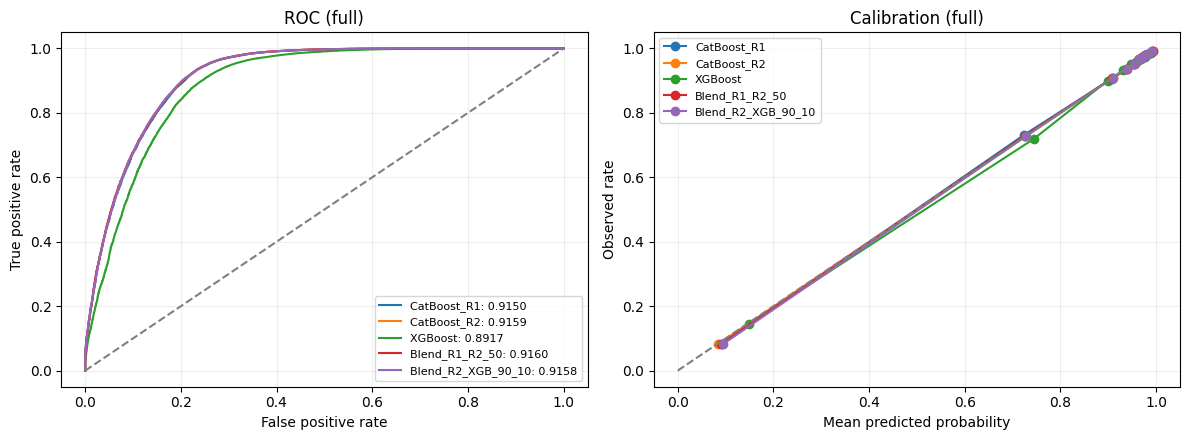

,model,dimension,group,n,positive,negative,actual_rate,predicted_rate,auc,brier,rejected_ap,mode
0,CatBoost_R1,LTV_missing,missing,11874,6391,5483,0.538235,0.537406,0.940480,0.095461,0.939986,full
1,CatBoost_R1,LTV_missing,observed,93126,82853,10273,0.889687,0.889663,0.887513,0.048633,0.735045,full
2,CatBoost_R1,DTI_missing,missing,7679,6315,1364,0.822373,0.826508,0.870450,0.084973,0.727628,full
3,CatBoost_R1,DTI_missing,observed,97321,82929,14392,0.852118,0.851667,0.917829,0.051479,0.824328,full
4,CatBoost_R1,DTI_form,exact,51610,47244,4366,0.915404,0.915729,0.856459,0.046581,0.627329,full
...,...,...,...,...,...,...,...,...,...,...,...,...
65,Blend_R2_XGB_90_10,property_value_missing,observed,100244,85926,14318,0.857169,0.858086,0.913471,0.052259,0.811062,full
66,Blend_R2_XGB_90_10,loan_type,1,77515,64956,12559,0.837980,0.838653,0.931420,0.052421,0.850920,full
67,Blend_R2_XGB_90_10,loan_type,2,17737,15444,2293,0.870722,0.873198,0.838458,0.060263,0.690017,full
68,Blend_R2_XGB_90_10,loan_type,3,8690,7927,763,0.912198,0.912543,0.843013,0.049089,0.618304,full


In [36]:
if oof is not None and run_status['state'] == 'complete':
    try:
        import matplotlib.pyplot as plt
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
        group_rows = []
        for name in SELECTED_MODELS + blend_summary['model'].tolist() if not blend_summary.empty else SELECTED_MODELS:
            mask = oof[f'prob_{name}'].notna().to_numpy()
            actual = oof.loc[mask, 'accepted'].to_numpy()
            probability = oof.loc[mask, f'prob_{name}'].to_numpy()
            fpr, tpr, _ = roc_curve(actual, probability)
            axes[0].plot(fpr, tpr, label=f'{name}: {roc_auc_score(actual, probability):.4f}')
            observed, predicted = calibration_curve(actual, probability, n_bins=10, strategy='quantile')
            axes[1].plot(predicted, observed, marker='o', label=name)
            group_definitions = {
                'LTV_missing': np.where(X.iloc[run_indices]['loan_to_value_ratio'].isna(), 'missing', 'observed'),
                'DTI_missing': np.where(X.iloc[run_indices]['debt_to_income_ratio'].eq('MISSING'), 'missing', 'observed'),
                'DTI_form': X.iloc[run_indices]['debt_to_income_ratio'].map(
                    DTI_BOUNDS_AND_FORM).map(lambda value: value[2]).to_numpy(),
                'property_value_missing': np.where(X.iloc[run_indices]['property_value'].isna(), 'missing', 'observed'),
                'loan_type': X.iloc[run_indices]['loan_type'].to_numpy(),
            }
            for dimension, values in group_definitions.items():
                for group in sorted(set(values)):
                    group_mask = mask & (values == group)
                    target = oof.loc[group_mask, 'accepted'].to_numpy()
                    pred = oof.loc[group_mask, f'prob_{name}'].to_numpy()
                    if len(target) == 0:
                        continue
                    positives = int(target.sum())
                    negatives = len(target) - positives
                    auc = roc_auc_score(target, pred) if min(positives, negatives) >= 20 else np.nan
                    group_rows.append({'model': name, 'dimension': dimension, 'group': group,
                        'n': len(target), 'positive': positives, 'negative': negatives,
                        'actual_rate': target.mean(), 'predicted_rate': pred.mean(),
                        'auc': auc, 'brier': brier_score_loss(target, pred),
                        'rejected_ap': average_precision_score(1 - target, 1 - pred) if min(positives, negatives) >= 20 else np.nan,
                        'mode': RUN_MODE})
        axes[0].plot([0, 1], [0, 1], '--', color='gray')
        axes[1].plot([0, 1], [0, 1], '--', color='gray')
        axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title=f'ROC ({RUN_MODE})')
        axes[1].set(xlabel='Mean predicted probability', ylabel='Observed rate', title=f'Calibration ({RUN_MODE})')
        for axis in axes:
            axis.legend(fontsize=8)
            axis.grid(alpha=.2)
        fig.tight_layout()
        fig.savefig(run_dir / 'oof_diagnostics.png', dpi=150)
        plt.show()
        group_diagnostics = pd.DataFrame(group_rows)
        group_diagnostics.to_csv(run_dir / 'group_diagnostics.csv', index=False)
        display(group_diagnostics)
        run_status['diagnostics_state'] = 'complete'
    except Exception as exc:
        run_status.update(state='failed', diagnostics_state='failed', error=repr(exc))
        raise
    finally:
        (run_dir / 'status.json').write_text(json.dumps(run_status, ensure_ascii=False, indent=2), encoding='utf-8')
else:
    print('没有本次新 OOF，跳过诊断。')

## 可选新模型：EBM / AutoGluon

`advanced` 默认运行一个外折做资源检查，使用 `HMDA_ADVANCED_MODEL` 选择 EBM 或 AutoGluon。只有设 `HMDA_ADVANCED_FOLDS=all` 才跑完整五折。新依赖建议放独立环境，外层验证标签不进入拟合；单折结果不用于宣布胜出。


In [37]:
# 可选 challenger：EBM（默认、CPU）或 AutoGluon Tabular。
# 仅 RUN_MODE='advanced' 执行，默认固定外层 fold 1 pilot；正式五折设 HMDA_ADVANCED_FOLDS=all。
# 按所选模型安装依赖：pip install interpret 或 pip install autogluon.tabular。
import importlib.metadata

def advanced_categorical_frames(x_fit, x_valid):
    """在外层训练折学习类别集合，验证折只复用，不访问任何标签。"""
    fit_frame = x_fit.loc[:, FEATURE_COLUMNS].copy().reset_index(drop=True)
    valid_frame = x_valid.loc[:, FEATURE_COLUMNS].copy().reset_index(drop=True)
    for column in CATEGORICAL_COLUMNS:
        # 原数据准备 notebook 已把缺失映射为字符串 MISSING。
        categories = sorted(fit_frame[column].dropna().astype(str).unique().tolist())
        dtype = pd.CategoricalDtype(categories=categories, ordered=False)
        fit_frame[column] = fit_frame[column].astype(dtype)
        valid_frame[column] = valid_frame[column].astype(dtype)
    return fit_frame, valid_frame


def advanced_folds_from_env(value):
    requested = value.strip().lower()
    if requested == 'all':
        return list(range(1, 6))
    try:
        fold = int(requested)
    except ValueError as exc:
        raise ValueError('HMDA_ADVANCED_FOLDS 必须是 all 或单个 1..5 的折号') from exc
    require(1 <= fold <= 5, 'HMDA_ADVANCED_FOLDS 必须是 all 或单个 1..5 的折号')
    return [fold]


def advanced_package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return 'not installed'


advanced_run_dir = None
advanced_summary = pd.DataFrame()
advanced_fold_results = pd.DataFrame()
advanced_oof = None

if RUN_MODE == 'advanced':
    requested_model = os.environ.get('HMDA_ADVANCED_MODEL', 'EBM').strip().lower()
    require(requested_model in {'ebm', 'autogluon'},
            'HMDA_ADVANCED_MODEL 必须是 EBM 或 AutoGluon')
    advanced_model = 'EBM' if requested_model == 'ebm' else 'AutoGluon'
    advanced_options = {}
    if advanced_model == 'AutoGluon':
        # time_limit 是每个外层训练折的上限；实际运行可能略超时。
        advanced_preset = os.environ.get('HMDA_ADVANCED_PRESET', 'high_quality').strip()
        require(advanced_preset in {'good_quality', 'high_quality', 'best_quality'},
                'HMDA_ADVANCED_PRESET 必须是 good_quality / high_quality / best_quality')
        advanced_time_limit = int(os.environ.get('HMDA_ADVANCED_TIME_LIMIT', '3600'))
        require(advanced_time_limit >= 60, 'HMDA_ADVANCED_TIME_LIMIT 至少 60 秒')
        advanced_options = {'preset': advanced_preset,
                            'time_limit_per_fold_seconds': advanced_time_limit}
    else:
        # 比官方默认 50,000 rounds / 14 bags 明显更省资源，正式实验可显式提高。
        ebm_max_rounds = int(os.environ.get('HMDA_EBM_MAX_ROUNDS', '200'))
        ebm_outer_bags = int(os.environ.get('HMDA_EBM_OUTER_BAGS', '2'))
        ebm_interactions = int(os.environ.get('HMDA_EBM_INTERACTIONS', '8'))
        require(50 <= ebm_max_rounds <= 2000 and 1 <= ebm_outer_bags <= 20
                and 0 <= ebm_interactions <= 56,
                'EBM 参数范围：rounds 50..2000、bags 1..20、interactions 0..56')
        advanced_options = {
            'feature_types': ['continuous' if col in NUMERIC_COLUMNS else 'nominal'
                              for col in FEATURE_COLUMNS],
            'max_rounds': ebm_max_rounds, 'outer_bags': ebm_outer_bags,
            'interactions': ebm_interactions, 'max_bins': 256,
            'max_interaction_bins': 32, 'early_stopping_rounds': 30,
            'validation_size': 0.15, 'n_jobs': N_THREADS, 'random_state': MODEL_SEED,
        }
        require(advanced_options['feature_types'].count('continuous') == 13
                and advanced_options['feature_types'].count('nominal') == 43,
                'EBM 需要 13 连续 / 43 名义类别特征')
    advanced_folds = advanced_folds_from_env(os.environ.get('HMDA_ADVANCED_FOLDS', '1'))
    advanced_formal = advanced_folds == list(range(1, 6))
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    advanced_run_dir = OUTPUT_ROOT / 'artifacts' / 'models' / f'{stamp}_advanced_{advanced_model.lower()}'
    advanced_run_dir.mkdir(parents=True, exist_ok=False)
    advanced_status = {'state': 'running', 'mode': 'advanced', 'model': advanced_model,
                       'formal_result': advanced_formal, 'completed_folds': 0}
    (advanced_run_dir / 'status.json').write_text(
        json.dumps(advanced_status, ensure_ascii=False, indent=2), encoding='utf-8')
    try:
        config = {
            'protocol': 'seed42_fixed_outer_folds_train_only_inside_outer_fold',
            'model': advanced_model, 'mode': 'advanced', 'formal_result': advanced_formal,
            'folds_run': advanced_folds, 'train_rows': len(X), 'model_seed': MODEL_SEED,
            'model_options': advanced_options,
            'categorical_vocabulary': 'learned on outer training fold only',
            'positive_class': 1, 'outer_cv': {'n_splits': 5, 'shuffle': True, 'random_state': 42},
            'data_hashes': DATA_HASHES, 'source_hashes': manifest['source_files'],
            'versions': {
                'python': platform.python_version(),
                'numpy': advanced_package_version('numpy'),
                'pandas': advanced_package_version('pandas'),
                'scikit-learn': advanced_package_version('scikit-learn'),
                'autogluon.tabular': advanced_package_version('autogluon.tabular'),
                'interpret': advanced_package_version('interpret'),
                'interpret-core': advanced_package_version('interpret-core'),
            },
        }
        notebook_path = PROJECT_DIR / '02_hmda_models.ipynb'
        if notebook_path.is_file():
            config['notebook_sha256'] = sha256_file(notebook_path)
        (advanced_run_dir / 'config.json').write_text(
            json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
        if advanced_model == 'AutoGluon':
            from autogluon.tabular import TabularPredictor
        else:
            import joblib
            from interpret.glassbox import ExplainableBoostingClassifier

        advanced_oof = pd.DataFrame({
            'id': train_ids.to_numpy(),
            'accepted': y.to_numpy(),
            'fold': fold_assignment,
            f'prob_{advanced_model}': np.full(len(X), np.nan),
        })
        advanced_fold_rows = []
        for fold in advanced_folds:
            fit_idx = np.flatnonzero(fold_assignment != fold)
            valid_idx = np.flatnonzero(fold_assignment == fold)
            require(len(fit_idx) > 0 and len(valid_idx) > 0, '外层折为空')
            require(np.intersect1d(fit_idx, valid_idx).size == 0, '外层训练与验证重叠')
            require(set(y.iloc[fit_idx]) == {0, 1} and set(y.iloc[valid_idx]) == {0, 1},
                    '外层训练或验证折只有一个类别')
            fit_frame, valid_frame = advanced_categorical_frames(
                X.iloc[fit_idx], X.iloc[valid_idx])
            started = time.perf_counter()
            if advanced_model == 'AutoGluon':
                fit_frame['accepted'] = y.iloc[fit_idx].to_numpy(dtype=int)
                fold_path = advanced_run_dir / f'autogluon_fold_{fold}'
                predictor = TabularPredictor(
                    label='accepted', problem_type='binary', eval_metric='roc_auc',
                    positive_class=1, path=str(fold_path), verbosity=2)
                # 内部 bagging / stacking / 调参只见到 fit_frame；外层验证标签不传给 fit。
                predictor.fit(fit_frame, presets=advanced_preset,
                              time_limit=advanced_time_limit, num_cpus=N_THREADS)
                require(predictor.positive_class == 1, 'AutoGluon 正类不是 accepted=1')
                probability = check_probability(np.asarray(predictor.predict_proba(
                    valid_frame, as_multiclass=False, as_pandas=False)).reshape(-1))
                model_path = fold_path
            else:
                # EBM 接受 NaN 与名义类别；类别词表只由本折训练集建立。
                for col in CATEGORICAL_COLUMNS:
                    fit_frame[col] = fit_frame[col].astype(object)
                    valid_frame[col] = valid_frame[col].astype(object)
                predictor = ExplainableBoostingClassifier(
                    feature_names=FEATURE_COLUMNS, **advanced_options)
                predictor.fit(fit_frame, y.iloc[fit_idx].to_numpy(dtype=int))
                require(list(predictor.classes_) == [0, 1], 'EBM 类别顺序不是 0,1')
                probability = check_probability(predictor.predict_proba(valid_frame)[:, 1])
                fold_path = advanced_run_dir / f'ebm_fold_{fold}'
                fold_path.mkdir(parents=True, exist_ok=False)
                model_path = fold_path / 'model.joblib'
                joblib.dump(predictor, model_path)
            require(len(probability) == len(valid_idx), f'{advanced_model} 验证预测长度不匹配')
            probability_column = f'prob_{advanced_model}'
            require(advanced_oof.loc[valid_idx, probability_column].isna().all(), 'OOF 重复写入')
            advanced_oof.loc[valid_idx, probability_column] = probability
            fold_row = {
                'model': advanced_model, 'fold': fold,
                'mode': 'advanced', 'formal_result': advanced_formal,
                'train_rows': len(fit_idx), 'valid_rows': len(valid_idx),
                'valid_auc': roc_auc_score(y.iloc[valid_idx], probability),
                'valid_logloss': log_loss(y.iloc[valid_idx], probability, labels=[0, 1]),
                'valid_brier': brier_score_loss(y.iloc[valid_idx], probability),
                'valid_rejected_ap': average_precision_score(1 - y.iloc[valid_idx], 1 - probability),
                'fit_seconds': time.perf_counter() - started,
                'model_path': str(model_path),
            }
            advanced_fold_rows.append(fold_row)
            advanced_fold_results = pd.DataFrame(advanced_fold_rows)
            advanced_fold_results.to_csv(advanced_run_dir / 'fold_results.csv', index=False)
            advanced_oof.to_csv(advanced_run_dir / 'oof_predictions.csv', index=False)
            advanced_status.update(completed_folds=len(advanced_fold_rows), last_completed_fold=fold)
            (advanced_run_dir / 'status.json').write_text(
                json.dumps(advanced_status, ensure_ascii=False, indent=2), encoding='utf-8')
            print(f'{advanced_model} fold {fold} | AUC {fold_row["valid_auc"]:.6f} '
                  f'| {fold_row["fit_seconds"]:.1f}s', flush=True)

        expected_coverage = pd.Series(fold_assignment).isin(advanced_folds)
        require(advanced_oof[probability_column].notna().equals(expected_coverage),
                f'{advanced_model} OOF 覆盖错误')
        valid_y = advanced_oof.loc[expected_coverage, 'accepted']
        valid_p = advanced_oof.loc[expected_coverage, probability_column]
        advanced_summary = pd.DataFrame([{
            'model': advanced_model, 'mode': 'advanced', 'formal_result': advanced_formal,
            'fold_count': len(advanced_folds), 'predicted_rows': int(expected_coverage.sum()),
            'mean_fold_auc': advanced_fold_results['valid_auc'].mean(),
            'std_fold_auc': advanced_fold_results['valid_auc'].std(ddof=1),
            'pooled_oof_auc': roc_auc_score(valid_y, valid_p),
            'pooled_oof_logloss': log_loss(valid_y, valid_p, labels=[0, 1]),
            'pooled_oof_brier': brier_score_loss(valid_y, valid_p),
            'pooled_rejected_ap': average_precision_score(1 - valid_y, 1 - valid_p),
            'total_fit_seconds': advanced_fold_results['fit_seconds'].sum(),
        }])
        advanced_summary.to_csv(advanced_run_dir / 'summary.csv', index=False)
        advanced_status.update(state='complete', completed_at=datetime.now(timezone.utc).isoformat())
        display(advanced_summary)
        print(f'{advanced_model} 运行已保存：{advanced_run_dir}')
    except Exception as exc:
        advanced_status.update(state='failed', error=repr(exc),
                               failed_at=datetime.now(timezone.utc).isoformat())
        raise
    finally:
        (advanced_run_dir / 'status.json').write_text(
            json.dumps(advanced_status, ensure_ascii=False, indent=2), encoding='utf-8')


## 可选概率校准

`calibrate` 在每个外折训练部分再划内部校准集，分别比较原概率、sigmoid 和 isotonic 的 AUC、LogLoss、Brier 与拒绝类 AP。外层验证标签只评分。默认仅跑一个外折，避免在未经检查时启动整轮训练。


In [38]:
# 可选校准路线：外层验证标签只在最终打分时使用。
# 配置：HMDA_RUN_MODE=calibrate；HMDA_CALIBRATION_MODEL=CatBoost_R1；
#       HMDA_CALIBRATION_FOLDS=1（探索）或 5（完整五折）；
#       HMDA_CALIBRATION_FRACTION=0.20。
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score


def calibration_logit(probability):
    probability = np.clip(check_probability(probability), 1e-6, 1 - 1e-6)
    return np.log(probability / (1 - probability)).reshape(-1, 1)


def calibration_metrics(target, probability):
    target = np.asarray(target, dtype=np.int8)
    probability = check_probability(probability)
    require(len(target) == len(probability) and set(target) == {0, 1},
            '校准评估要求长度一致且包含两类标签')
    return {
        'accepted_auc': float(roc_auc_score(target, probability)),
        'logloss': float(log_loss(target, probability, labels=[0, 1])),
        'brier': float(brier_score_loss(target, probability)),
        'rejected_ap': float(average_precision_score(1 - target, 1 - probability)),
    }


calibration_dir = None
calibration_summary = pd.DataFrame()
if RUN_MODE == 'calibrate':
    calibration_model = os.environ.get('HMDA_CALIBRATION_MODEL', 'CatBoost_R1').strip()
    calibration_fold_count = int(os.environ.get('HMDA_CALIBRATION_FOLDS', '1'))
    calibration_fraction = float(os.environ.get('HMDA_CALIBRATION_FRACTION', '0.20'))
    require(calibration_model in {'CatBoost_R1', 'CatBoost_R2'},
            '校准只支持 CatBoost_R1 或 CatBoost_R2')
    require(1 <= calibration_fold_count <= 5, 'HMDA_CALIBRATION_FOLDS 必须在 1..5')
    require(0.05 <= calibration_fraction <= 0.40,
            'HMDA_CALIBRATION_FRACTION 必须在 0.05..0.40')
    if 'catboost' not in DEPENDENCY_MODULES:
        DEPENDENCY_MODULES['catboost'] = importlib.import_module('catboost')
    calibration_folds = list(range(1, calibration_fold_count + 1))
    calibration_dir = (OUTPUT_ROOT / 'artifacts' / 'models' /
                       f'{datetime.now(timezone.utc):%Y%m%dT%H%M%S_%fZ}_calibrate')
    calibration_dir.mkdir(parents=True, exist_ok=False)
    calibration_config = {
        'mode': 'calibrate', 'formal_result': calibration_fold_count == 5,
        'model': calibration_model, 'model_params': effective_params(calibration_model),
        'outer_folds': calibration_folds, 'outer_fold_seed': 42,
        'inner_calibration_fraction': calibration_fraction,
        'inner_split_seed_rule': 'MODEL_SEED + outer_fold',
        'protocol': ('For each outer fold, split outer-train into fit/calibration; '
                     'fit base model on inner-fit; fit sigmoid and isotonic on '
                     'inner-calibration predictions and labels; score all three '
                     'on untouched outer-valid. No refit after calibration.'),
        'data_hashes': DATA_HASHES,
        'python_version': platform.python_version(),
        'catboost_version': importlib.metadata.version('catboost'),
    }
    calibration_notebook = PROJECT_DIR / '02_hmda_models.ipynb'
    if calibration_notebook.exists():
        calibration_config['notebook_sha256'] = sha256_file(calibration_notebook)
    (calibration_dir / 'config.json').write_text(
        json.dumps(calibration_config, ensure_ascii=False, indent=2), encoding='utf-8')
    calibration_status = {'state': 'running', 'completed_folds': 0,
                          'formal_result': calibration_fold_count == 5}
    calibration_fold_rows = []
    calibration_oof_parts = []
    (calibration_dir / 'status.json').write_text(
        json.dumps(calibration_status, ensure_ascii=False, indent=2), encoding='utf-8')
    try:
        for fold in calibration_folds:
            outer_fit_idx = np.flatnonzero(fold_assignment != fold)
            outer_valid_idx = np.flatnonzero(fold_assignment == fold)
            inner_fit_idx, inner_cal_idx = train_test_split(
                outer_fit_idx, test_size=calibration_fraction,
                stratify=y.iloc[outer_fit_idx].to_numpy(),
                random_state=MODEL_SEED + fold)
            require(not np.intersect1d(inner_fit_idx, inner_cal_idx).size and
                    not np.intersect1d(outer_fit_idx, outer_valid_idx).size and
                    not np.intersect1d(inner_cal_idx, outer_valid_idx).size,
                    '校准路线的训练、校准、外层验证集合重叠')
            require(set(y.iloc[inner_fit_idx]) == set(y.iloc[inner_cal_idx]) ==
                    set(y.iloc[outer_valid_idx]) == {0, 1},
                    '每个训练、校准、外层验证分区都必须包含两类')
            cal_probability, base_model, _, fit_info = fit_model(
                calibration_model, X.iloc[inner_fit_idx], y.iloc[inner_fit_idx],
                X.iloc[inner_cal_idx])
            calibrate_started = time.perf_counter()
            sigmoid = LogisticRegression(solver='lbfgs', C=1.0, max_iter=1000)
            sigmoid.fit(calibration_logit(cal_probability), y.iloc[inner_cal_idx])
            isotonic = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds='clip')
            isotonic.fit(cal_probability, y.iloc[inner_cal_idx].to_numpy())
            calibration_fit_seconds = time.perf_counter() - calibrate_started
            raw_valid = check_probability(base_model.predict_proba(X.iloc[outer_valid_idx])[:, 1])
            sigmoid_valid = check_probability(sigmoid.predict_proba(calibration_logit(raw_valid))[:, 1])
            isotonic_valid = check_probability(isotonic.predict(raw_valid))
            candidates = {'raw': raw_valid, 'sigmoid': sigmoid_valid,
                          'isotonic': isotonic_valid}
            for method, probability in candidates.items():
                calibration_fold_rows.append({
                    'model': calibration_model, 'method': method, 'fold': fold,
                    'inner_fit_rows': len(inner_fit_idx),
                    'inner_calibration_rows': len(inner_cal_idx),
                    'outer_valid_rows': len(outer_valid_idx),
                    'base_fit_seconds': fit_info['fit_seconds'],
                    'calibration_fit_seconds': calibration_fit_seconds,
                    'base_rounds': fit_info['best_round'],
                    **calibration_metrics(y.iloc[outer_valid_idx], probability),
                })
            fold_oof = pd.DataFrame({
                'row_index': outer_valid_idx, 'id': train_ids.iloc[outer_valid_idx].to_numpy(),
                'accepted': y.iloc[outer_valid_idx].to_numpy(), 'fold': fold,
                **{f'prob_{method}': values for method, values in candidates.items()},
            })
            calibration_oof_parts.append(fold_oof)
            pd.DataFrame(calibration_fold_rows).to_csv(
                calibration_dir / 'fold_results.csv', index=False)
            pd.concat(calibration_oof_parts).sort_values('row_index').to_csv(
                calibration_dir / 'oof_predictions.csv', index=False)
            calibration_status['completed_folds'] = fold
            (calibration_dir / 'status.json').write_text(
                json.dumps(calibration_status, ensure_ascii=False, indent=2), encoding='utf-8')
            print(f'{calibration_model} 校准 fold {fold}: '
                  f'raw AUC={calibration_fold_rows[-3]["accepted_auc"]:.6f}, '
                  f'sigmoid Brier={calibration_fold_rows[-2]["brier"]:.6f}, '
                  f'isotonic Brier={calibration_fold_rows[-1]["brier"]:.6f}', flush=True)
        calibration_oof = pd.concat(calibration_oof_parts).sort_values('row_index')
        require(calibration_oof['row_index'].is_unique, '校准 OOF 行重复')
        expected_idx = np.flatnonzero(np.isin(fold_assignment, calibration_folds))
        require(np.array_equal(calibration_oof['row_index'].to_numpy(), expected_idx),
                '校准 OOF 覆盖与计划折不一致')
        summary_rows = []
        for method in ('raw', 'sigmoid', 'isotonic'):
            part = pd.DataFrame(calibration_fold_rows).query('method == @method')
            pooled = calibration_metrics(calibration_oof['accepted'],
                                         calibration_oof[f'prob_{method}'])
            summary_rows.append({
                'model': calibration_model, 'method': method,
                'formal_result': calibration_fold_count == 5,
                'fold_count': len(part), 'predicted_rows': len(calibration_oof),
                'mean_fold_auc': float(part['accepted_auc'].mean()),
                'mean_fold_logloss': float(part['logloss'].mean()),
                'mean_fold_brier': float(part['brier'].mean()),
                'mean_fold_rejected_ap': float(part['rejected_ap'].mean()),
                **{f'pooled_{name}': value for name, value in pooled.items()},
            })
        calibration_summary = pd.DataFrame(summary_rows)
        raw_auc = calibration_summary.loc[calibration_summary['method'].eq('raw'),
                                          'mean_fold_auc'].iloc[0]
        raw_brier = calibration_summary.loc[calibration_summary['method'].eq('raw'),
                                            'mean_fold_brier'].iloc[0]
        calibration_summary['mean_fold_auc_delta_vs_raw'] = (
            calibration_summary['mean_fold_auc'] - raw_auc)
        calibration_summary['mean_fold_brier_delta_vs_raw'] = (
            calibration_summary['mean_fold_brier'] - raw_brier)
        calibration_summary.to_csv(calibration_dir / 'summary.csv', index=False)
        calibration_status.update(state='complete',
                                  completed_at=datetime.now(timezone.utc).isoformat())
        display(calibration_summary)
        print(f'校准产物：{calibration_dir}')
    except Exception as exc:
        calibration_status.update(state='failed', error=repr(exc))
        raise
    finally:
        (calibration_dir / 'status.json').write_text(
            json.dumps(calibration_status, ensure_ascii=False, indent=2), encoding='utf-8')


## 11. 可选：全量训练与本地预测

默认关闭。只有同一轮 `full` 五折完成，才可将 `FIT_FINAL_MODEL=True` 并指定已参与验证的 `FINAL_MODEL_NAME`。可选单模型或预设融合 `Blend_R1_R2_50` 等；保存完整模型包和与 `sample_submission.csv` 顺序一致的本地 CSV，不上传。新数据预测先执行本 notebook 的类定义，再加载 joblib 并调用 `predict_saved_bundle(bundle, features)`。


In [39]:
def predict_saved_bundle(bundle, features):
    require(features.columns.tolist() == bundle['feature_columns'], '待预测数据必须匹配原始特征顺序')
    if 'models' in bundle:
        return check_probability(sum(
            item['weight'] * predict_saved_bundle(item['bundle'], features)
            for item in bundle['models']))
    name = bundle['model_name']
    transformed = features
    vocabulary = bundle['vocabulary']
    if isinstance(vocabulary, HmdaFeatureVariant):
        transformed = vocabulary.transform(features)
    elif isinstance(vocabulary, NativeCategoryVocabulary):
        transformed = vocabulary.transform(features)
    return check_probability(bundle['model'].predict_proba(transformed)[:, 1])


if FIT_FINAL_MODEL:
    try:
        require(RUN_MODE == 'full' and run_status['state'] == 'complete', '最终训练要求完整五折成功')
        weights = BLEND_SPECS.get(FINAL_MODEL_NAME, {FINAL_MODEL_NAME: 1.0})
        require(set(weights) <= set(SELECTED_MODELS), '最终模型或融合成分必须参与本次完整五折')
        require(oof[f'prob_{FINAL_MODEL_NAME}'].notna().all(), '最终模型或融合缺少完整 OOF')
        require(test_ids.equals(sample_submission['id']), '提交 ID 顺序不符')
        components, component_info = [], []
        for name, weight in weights.items():
            fixed_rounds = None
            if MODEL_REGISTRY[name]['family'] == 'native':
                fixed_rounds = int(np.rint(fold_results.loc[
                    fold_results['model'].eq(name), 'best_round'].median()))
            pred, model, vocabulary, info = fit_model(
                name, X, y, X_test, fixed_rounds=fixed_rounds)
            component_bundle = {'model': model, 'vocabulary': vocabulary,
                                'feature_columns': FEATURE_COLUMNS, 'model_name': name}
            components.append({'name': name, 'weight': weight, 'pred': pred,
                               'bundle': component_bundle})
            component_info.append({'model': name, 'weight': weight,
                                   'fixed_rounds_from_cv': fixed_rounds, **info})
        final_probability = check_probability(sum(item['weight'] * item['pred'] for item in components))
        submission = pd.DataFrame({'id': sample_submission['id'], 'accepted': final_probability})
        require(len(submission) == len(X_test), '提交长度不符')
        output_path = run_dir / f'submission_{FINAL_MODEL_NAME}.csv'
        submission.to_csv(output_path, index=False)
        reread = pd.read_csv(output_path, dtype={'id': str}, keep_default_na=False)
        require(reread['id'].equals(sample_submission['id']), '写出后 ID 顺序检查失败')
        check_probability(reread['accepted'].to_numpy())
        import joblib
        if len(components) == 1:
            bundle = dict(components[0]['bundle'])
        else:
            bundle = {'models': [{'name': item['name'], 'weight': item['weight'],
                                  'bundle': item['bundle']} for item in components],
                      'feature_columns': FEATURE_COLUMNS, 'model_name': FINAL_MODEL_NAME}
        bundle.update(versions=config['versions'], data_hashes=DATA_HASHES)
        joblib.dump(bundle, run_dir / f'final_{FINAL_MODEL_NAME}.joblib')
        (run_dir / 'final_training.json').write_text(json.dumps({
            'model': FINAL_MODEL_NAME, 'components': component_info,
            'submission_sha256': sha256_file(output_path), 'submission_rows': len(submission),
        }, ensure_ascii=False, indent=2), encoding='utf-8')
        display(submission.head())
        print(f'已生成本地文件：{output_path}')
        run_status['final_state'] = 'complete'
    except Exception as exc:
        run_status.update(state='failed', final_state='failed', error=repr(exc))
        raise
    finally:
        (run_dir / 'status.json').write_text(json.dumps(run_status, ensure_ascii=False, indent=2), encoding='utf-8')
else:
    print('最终训练/生成提交：关闭。')


最终训练/生成提交：关闭。
